## 0. Configuración

In [ ]:
import os
# --- Qué se ejecuta -------------------------------------------------------------------------------
EJECUTAR = {'S2': True, 'S3': True}   # sesión solo CPU → {'S2': True, 'S3': False}; sesión GPU → {'S2': False, 'S3': True}
REPS = list(range(1, 11))   # para repartir entre sesiones: [1, 2, 3, 4, 5] en una y [6, 7, 8, 9, 10] en otra
REANUDAR = True            # reutiliza lo ya guardado en Drive (por REP y por parte)

# --- Rutas ----------------------------------------------------------------------------------------
CARPETA = os.environ.get('CARPETA_ARTICULO', '/content/drive/MyDrive/Articulo_Grupal_EdgeIIoT')
RUTA_CSV = os.environ.get('EDGE_CSV', os.path.join(CARPETA, 'DNN-EdgeIIoT-dataset.csv'))
DIR_V1 = os.path.join(CARPETA, 'corridas')                 # resultados v1 (solo lectura)
DIR_MEJ = os.path.join(CARPETA, 'mejoras')                 # todo lo nuevo
DIR_TMP = os.environ.get('DIR_TMP_S11D', '/content/tmp_s11d')   # disco local: datos de medición y modelos de paso
NB_CONSOLIDACION = os.environ.get('NB_CONSOLIDACION', '/content/drive/MyDrive/Colab Notebooks/S11_Consolidacion_Estadistica.ipynb')

# --- Parámetros de v1 (sección 13; no modificar) ---------------------------------------------------
TEST_SIZE = 0.30
SMOTE_K = 5
MI_SUBMUESTRA = 200_000
MI_MAX_DISCRETO = 64
MI_BINS = 32
LOTE_MEDICION = 1024
V1_VERSIONES = {'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1'}   # las de las fichas v1
COLS_RETIRAR = ['frame.time', 'ip.dst_host', 'http.file_data', 'ip.src_host', 'arp.src.proto_ipv4',
                'arp.dst.proto_ipv4', 'http.request.full_uri', 'http.request.uri.query',
                'icmp.transmit_timestamp', 'tcp.payload', 'tcp.options', 'tcp.srcport',
                'tcp.dstport', 'udp.port', 'mqtt.msg']
COLS_CATEGORICAS = ['http.request.method', 'http.referer', 'http.request.version',
                    'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']
GAO_18 = ['icmp.checksum', 'icmp.seq_le', 'http.response', 'tcp.ack', 'tcp.ack_raw',
          'tcp.connection.rst', 'tcp.connection.syn', 'udp.stream', 'dns.qry.name',
          'http.request.method-0', 'http.request.method-GET', 'http.request.method-POST',
          'http.referer-0', 'http.request.version-0', 'dns.qry.name.len-0.0',
          'mqtt.conack.flags-0.0', 'mqtt.protoname-0.0', 'mqtt.topic-0.0']
NOMBRE = {'tcn': 'TCN', 'rf': 'MI-LiteRF', 'xgb': 'MI-LiteXGB'}
ALFA = 0.05

# --- M1: benchmark de despliegue ---------------------------------------------------------------------
M1_N_LOTE1 = 10_000          # flujos para la latencia con lote de 1 en ONNX Runtime (mediana por flujo)
M1_N_LOTE1_NATIVO = 2_000    # en el runtime de v1 (Keras / scikit-learn / XGBoost), solo como referencia
M1_CALENTAMIENTO_LOTE1 = 500 # llamadas de calentamiento descartadas antes de medir con lote de 1
M1_OPSET = 17                # opset ONNX para la TCN y el RF (onnxmltools admite hasta 15 para XGBoost)

# --- M2: ablación (regla de lectura fijada antes) ------------------------------------------------------
MARGEN_RELEVANTE = 1.0       # puntos de F1 macro: diferencia mínima con relevancia práctica
#   Por brazo: Δ = F1(MI-LiteRF) − F1(brazo), prueba pareada bilateral (Shapiro → t o Wilcoxon), Holm sobre los 3 brazos.
#   «A favor de MI-LiteRF» si p Holm < 0,05 y Δ ≥ margen; «en contra» si p Holm < 0,05 y Δ ≤ −margen; si no, «sin diferencia relevante».

# --- M3: MI-LiteRF v2 compacto (REGLA PENDIENTE DE APROBACIÓN) ---------------------------------------
M3_K_GRID = [10, 15, 18, 20, 25]
M3_PROF_GRID = [8, 10, 12, 15]
M3_ARBOLES_GRID = [10, 15, 25]
M3_T = 2000                  # balanceo de v1
M3_TOLERANCIA = 0.99         # candidatos: F1 macro CV ≥ 99 % del mejor de la rejilla
M3_K_MAX = 18                # ... y no más atributos que la TCN
M3_FILTRO_SU = True          # True: ranking IM + descarte de redundantes por incertidumbre simétrica (SU)
M3_TAU_SU = 0.99             # un atributo es redundante si SU ≥ 0,99 con uno ya elegido
M3_CV_POR_REP = True         # True: CV dentro de cada REP (como v1). False: CV solo en REP-01 y se aplica a todas
M3_CRITERIO_TAMANO = 'tamano_kb'   # 'tamano_kb' = joblib sin comprimir (indicador 14.3); 'tamano_c3_kb' = joblib compress=3
REGLA_M3_APROBADA = True     # aprobada por Leonardo el 16/11/2026: opción B (IM + filtro SU) y CV en cada REP
M3_VISTA_PREVIA = True       # muestra el ranking con filtro SU de la 1.ª REP (solo entrenamiento) aunque M3 esté bloqueada

# --- M4: sensibilidad al artefacto «0»/«0.0» (opcional) ------------------------------------------------
M4_CONFIG = 'v1'             # 'v1' (k, T, RF y XGB de v1) o 'v2' (la configuración elegida en M3)

# --- S2: MI-LiteRF v3, balanceo elegido por CV (regla fijada antes de mirar el conjunto de prueba) ----------
S2_T_GRID = [2000, 5000, 10000, 20000, None]   # None = sin balanceo (entrenamiento completo)
S2_TOLERANCIA = 0.99                           # misma parsimonia de v1: F1 CV ≥ 99 % del mejor; el más pequeño (joblib)
REGLA_S2_APROBADA = True                      # 🔒

# --- S3/S4/S5: escenario sin artefacto (regla fijada antes de mirar el conjunto de prueba) -------------------
# TCN de v1 (S10, sección 7), sin cambios: mismos hiperparámetros y mismos 18 atributos de Gao, con las variables «-0.0»
# reemplazadas por su versión unificada «-0» (al unificar «0.0» → «0», la variable «-0.0» deja de existir).
TCN_CFG = dict(lr=1e-3, epocas=50, lote=128, dilataciones=[1, 2, 4, 8], kernel=1, filtros=26, dropout=0.1, val_split=0.1)
S3_MAPEO_GAO = {'dns.qry.name.len-0.0': 'dns.qry.name.len-0', 'mqtt.conack.flags-0.0': 'mqtt.conack.flags-0',
                'mqtt.protoname-0.0': 'mqtt.protoname-0', 'mqtt.topic-0.0': 'mqtt.topic-0'}
S5_TFP_MAX = 1.0                               # % — índice «óptimo» de la matriz 10.2
S5_TAU_GRID = [round(0.05 * i, 2) for i in range(1, 20)]   # 0,05 … 0,95 (además de «argmax»)
S3_EXIGIR_GPU = True                           # la TCN necesita GPU (en CPU tardaría horas por REP)
REGLA_S3_APROBADA = True                      # 🔒

os.makedirs(DIR_TMP, exist_ok=True)      # disco local; las carpetas de Drive se crean después de montarlo (0.1)
print('REPS:', REPS, '| partes:', [p for p, v in EJECUTAR.items() if v], '| salida:', DIR_MEJ)

REPS: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | partes: ['S2', 'S3'] | salida: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras


## 0.1 Drive, versiones y librerías
Se fijan scikit-learn, imbalanced-learn y XGBoost en las versiones de las fichas v1: así los `.joblib` guardados cargan sin cambios y el balanceo se reproduce exactamente. Si Colab trae otras versiones, la celda las instala y te pide reiniciar la sesión una vez.

In [ ]:
import sys, subprocess, json, time, platform, datetime, io, gc, glob, gzip, shutil, warnings, math
import importlib.metadata as im
from types import SimpleNamespace
EN_COLAB = 'google.colab' in sys.modules
ficha_rep1 = os.path.join(DIR_V1, 'REP-01', 'ficha_REP-01.json')
if EN_COLAB and not os.path.exists(ficha_rep1):          # Drive aún no montado (si ya se montó desde el panel, no se vuelve a pedir)
    # Solo se quitan carpetas VACÍAS que este notebook pudo crear antes de montar (os.rmdir nunca borra archivos)
    for d in (DIR_MEJ, CARPETA, '/content/drive/MyDrive', '/content/drive'):
        try:
            os.rmdir(d)
        except OSError:
            pass
    from google.colab import drive
    try:
        drive.mount('/content/drive')
    except Exception as e:
        raise SystemExit(f'⛔ No se pudo montar Drive ({e}). Móntalo desde el panel Archivos (ícono de carpeta → '
                         'botón de Drive) y vuelve a ejecutar esta celda.')
if not os.path.exists(ficha_rep1):
    raise SystemExit(f'⛔ No encuentro {ficha_rep1}. Revisa que el Drive montado sea el de la cuenta dueña de '
                     'Articulo_Grupal_EdgeIIoT (Entorno de ejecución → Desconectar y borrar entorno, y vuelve a montar).')
os.makedirs(DIR_MEJ, exist_ok=True)

def version(paquete):
    try:
        return im.version(paquete)
    except im.PackageNotFoundError:
        return None

distintas = {p: version(p) for p, v in V1_VERSIONES.items() if version(p) != v}
if distintas:
    ya_cargadas = [m for m in ('sklearn', 'imblearn', 'xgboost') if m in sys.modules]
    print('Instalando las versiones de v1 (ahora hay', distintas, ')')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
    if ya_cargadas:
        raise SystemExit('⛔ Se cambiaron librerías que ya estaban cargadas. Reinicia la sesión '
                         '(Entorno de ejecución → Reiniciar sesión) y vuelve a ejecutar desde el inicio.')
faltan = [p for p in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'papermill', 'kagglehub', 'openpyxl') if version(p) is None]
if faltan:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan,
                    *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
if version('tf2onnx') is None:   # sin dependencias para no tocar protobuf ni TensorFlow
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'tf2onnx'], check=True)

import numpy as np, pandas as pd, psutil, joblib
import sklearn, imblearn, xgboost, scipy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

def cpu_modelo():
    try:
        for l in open('/proc/cpuinfo'):
            if l.startswith('model name'):
                return l.split(':', 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

ENTORNO = {
    'fecha_hora': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'),
    'evaluadores': 'Leonardo Leoncio Villanueva Fonseca; Ricardo Franco Baldoceda Rios',
    'archivo_datos': os.path.basename(RUTA_CSV),
    'procesador': cpu_modelo(), 'nucleos_logicos': psutil.cpu_count(),
    'ram_total_gb': round(psutil.virtual_memory().total / 1024**3, 2),
    'medicion': 'CPU, 1 hilo, un proceso por modelo',
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'imbalanced_learn': imblearn.__version__,
    'xgboost': xgboost.__version__, 'tensorflow': version('tensorflow'), 'keras': version('keras'),
    'scipy': scipy.__version__, 'onnx': version('onnx'), 'onnxruntime': version('onnxruntime'),
    'skl2onnx': version('skl2onnx'), 'onnxmltools': version('onnxmltools'), 'tf2onnx': version('tf2onnx'),
}

# Comparación con el entorno de las fichas v1
ENTORNO_V1 = json.load(open(ficha_rep1, encoding='utf-8'))['tabla_14_2']
claves = ['procesador', 'nucleos_logicos', 'ram_total_gb', 'python', 'numpy', 'pandas', 'scikit_learn',
          'imbalanced_learn', 'xgboost', 'tensorflow', 'keras', 'scipy']
comp = pd.DataFrame({'v1 (REP-01)': [ENTORNO_V1.get(c) for c in claves], 'esta sesión': [ENTORNO.get(c) for c in claves]}, index=claves)
comp['igual'] = ['✔' if str(a) == str(b) else '≠' for a, b in zip(comp.iloc[:, 0], comp.iloc[:, 1])]
for c in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'tf2onnx'):
    comp.loc[c] = ['—', ENTORNO[c], '']
if shutil.which('nvidia-smi') and 'GPU' in subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout:
    print('ℹ️ Hay GPU en la sesión: S3 la usa para reentrenar la TCN (S2 no la necesita).')
comp

Mounted at /content/drive
ℹ️ Hay GPU en la sesión: S3 la usa para reentrenar la TCN (S2 no la necesita).


,v1 (REP-01),esta sesión,igual
procesador,Intel(R) Xeon(R) CPU @ 2.00GHz,Intel(R) Xeon(R) CPU @ 2.20GHz,≠
nucleos_logicos,8,12,≠
ram_total_gb,50.99,52.96,≠
python,3.13.16,3.13.16,✔
numpy,2.4.6,2.4.6,✔
pandas,2.2.3,2.2.3,✔
scikit_learn,1.6.1,1.6.1,✔
imbalanced_learn,0.14.2,0.14.2,✔
xgboost,3.4.1,3.4.1,✔
tensorflow,2.21.0,2.21.0,✔


## 0.2 Utilidades comunes
Funciones copiadas de S10 sin cambios (entropía, discretización, balanceo, indicadores) y las pruebas pareadas del notebook de consolidación.

In [ ]:
def guardar_json(obj, ruta):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else (o.tolist() if hasattr(o, 'tolist') else str(o)))

def leer_json(ruta):
    with open(ruta, encoding='utf-8') as f:
        return json.load(f)

def hay(ruta):
    return REANUDAR and os.path.exists(ruta)

def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    if parte == 'M3' and not REGLA_M3_APROBADA:
        print('🔒 M3 bloqueada: falta aprobar la regla (REGLA_M3_APROBADA = True en la configuración).')
        return False
    return True

def bitacora(parte, rep, inicio, nota=''):
    ruta = os.path.join(DIR_MEJ, f'bitacora_{parte}.csv')
    fila = pd.DataFrame([{'parte': parte, 'rep': rep, 'inicio': time.strftime('%d/%m/%Y %H:%M:%S', time.localtime(inicio)),
                          'segundos': round(time.time() - inicio, 1), 'nota': nota}])
    fila.to_csv(ruta, mode='a', header=not os.path.exists(ruta), index=False)

def kb_joblib(modelo, compress=0):
    b = io.BytesIO(); joblib.dump(modelo, b, compress=compress); return b.tell() / 1024

def kb_gzip(ruta):
    with open(ruta, 'rb') as f:
        return len(gzip.compress(f.read(), compresslevel=9)) / 1024

# --- Información mutua (S10, sección 8) ---------------------------------------------------------------
def entropia(*codigos):
    c = codigos[0].astype(np.int64)
    for otro in codigos[1:]:                       # entropía conjunta: código combinado
        c = c * (int(otro.max()) + 1) + otro.astype(np.int64)
    _, cnt = np.unique(c, return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def discretizar(x):
    u = np.unique(x)
    if len(u) <= MI_MAX_DISCRETO:
        return np.searchsorted(u, x)
    bordes = np.unique(np.quantile(x, np.linspace(0, 1, MI_BINS + 1)[1:-1]))
    return np.digitize(x, bordes)

# --- Balanceo (S10, sección 9): submuestreo → SMOTE → Tomek -------------------------------------------
def balancear(Xs, ys, T, semilla):
    cnt = np.bincount(ys, minlength=N_CLASES)
    bajo = {c: T for c in range(N_CLASES) if cnt[c] > T}
    if bajo:
        Xs, ys = RandomUnderSampler(sampling_strategy=bajo, random_state=semilla).fit_resample(Xs, ys)
    cnt = np.bincount(ys, minlength=N_CLASES)
    sobre = {c: T for c in range(N_CLASES) if 0 < cnt[c] < T}
    if sobre:
        kn = min(SMOTE_K, int(cnt[list(sobre)].min()) - 1)
        Xs, ys = SMOTE(sampling_strategy=sobre, k_neighbors=kn, random_state=semilla).fit_resample(Xs, ys)
    Xs, ys = TomekLinks(sampling_strategy='all', n_jobs=-1).fit_resample(Xs, ys)
    return np.ascontiguousarray(Xs, dtype=np.float32), ys

# --- Indicadores (S10, sección 13; el retardo sigue «no calculable», como en v1) ------------------------
def indicadores(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(N_CLASES))
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0) * 100
    TN = cm[NORMAL, NORMAL]; FP = cm[NORMAL].sum() - TN
    return {'f1_macro': float(f1.mean()), 'f1_por_clase': dict(zip(CLASES, f1.tolist())),
            'tfp': float(FP / (FP + TN) * 100), 'falsas_alarmas': int(FP),
            'exactitud': float(accuracy_score(y_real, y_pred) * 100),
            'f1_ponderado': float(f1_score(y_real, y_pred, average='weighted') * 100),
            'matriz_confusion': cm.tolist(),
            'retardo_mediana_ms': 'no calculable', 'episodios_no_detectados': 'no calculable'}

def f1_macro(y_real, y_pred):
    return f1_score(y_real, y_pred, average='macro', labels=range(N_CLASES), zero_division=0) * 100

# --- Pruebas pareadas + Holm (iguales al notebook de consolidación) -------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    orden = np.argsort(p, kind='mergesort'); ajust = np.empty(m); acumulado = 0.0
    for i, idx in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (m - i) * p[idx])); ajust[idx] = acumulado
    return ajust

def prueba_pareada(o1, o2, alternativa, alfa=ALFA):
    """Shapiro–Wilk de d = O2 − O1; t pareada si es normal, si no Wilcoxon. alternativa: 'two-sided', 'greater', 'less'."""
    o1, o2 = np.asarray(o1, float), np.asarray(o2, float)
    r = {'n': int(len(o1)), 'media_O1': float(np.mean(o1)), 'media_O2': float(np.mean(o2)), 'alternativa': alternativa,
         'media_d': float(np.mean(o2 - o1)), 'de_d': float(np.std(o2 - o1, ddof=1)) if len(o1) > 1 else np.nan,
         'shapiro_p': np.nan, 'prueba': '—', 'estadistico': np.nan, 'gl': np.nan, 'p': 1.0, 'dz': np.nan,
         'ic95_d': (np.nan, np.nan), 'evaluable': False}
    d = o2 - o1
    if len(d) < 3 or np.allclose(d, 0):
        r['estado'] = 'Sin diferencias' if len(d) >= 3 else 'n < 3'
        return r
    r['evaluable'] = True
    normal = False
    if r['de_d'] > 0:
        r['shapiro_p'] = float(stats.shapiro(d).pvalue); normal = r['shapiro_p'] > alfa
    if r['de_d'] > 0:
        h = stats.t.ppf(0.975, len(d) - 1) * r['de_d'] / np.sqrt(len(d))
        r['ic95_d'] = (r['media_d'] - h, r['media_d'] + h)
    if normal:
        t = stats.ttest_rel(o2, o1, alternative=alternativa)
        r.update(prueba='t pareada', estadistico=float(t.statistic), gl=int(len(d) - 1), p=float(t.pvalue),
                 dz=r['media_d'] / r['de_d'])
    else:
        w = stats.wilcoxon(d, alternative=alternativa)
        r.update(prueba='Wilcoxon', estadistico=float(w.statistic), p=float(w.pvalue))
    r['estado'] = 'Evaluada'
    return r

def media_de(s):
    s = pd.Series(s, dtype=float)
    return f'{s.mean():.4g} ± {s.std(ddof=1):.2g}' if len(s) > 1 else f'{s.mean():.4g}'

# --- Estilo de figuras (el mismo de la sección 16) --------------------------------------------------------
COLOR = {'tcn': '#2a78d6', 'rf': '#eb6834', 'xgb': '#1baf7a'}
MARCA = {'tcn': 'o', 'rf': 's', 'xgb': '^'}
TINTA, TINTA2, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.titlesize': 10})
coma = matplotlib.ticker.FuncFormatter(lambda x, _: f'{x:g}'.replace('.', ','))

## 1. Preprocesamiento común (idéntico a S10, secciones 3 y 4)
Se lee el CSV, se retiran los 15 atributos, faltantes y duplicados, y se codifican los 7 categóricos con los nombres de Gao. `frame.time` no se lee: en v1 se apartaba antes de quitar faltantes y duplicados, así que el resultado es el mismo. Con `unificar_ceros=True` (solo M4) se unifica «0.0» → «0» **después** de quitar duplicados, para conservar exactamente las mismas filas y la misma división de v1.

In [ ]:
def preprocesar(unificar_ceros=False):
    t0 = time.perf_counter()
    if not os.path.exists(RUTA_CSV):
        import kagglehub
        ruta = kagglehub.dataset_download('mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot',
                                          path='Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv')
        globals()['RUTA_CSV'] = ruta if ruta.endswith('.csv') else glob.glob(os.path.join(ruta, '**', 'DNN-EdgeIIoT-dataset.csv'), recursive=True)[0]
    retirar = set(COLS_RETIRAR)
    df = pd.read_csv(RUTA_CSV, low_memory=False, usecols=lambda c: c.strip() not in retirar)
    df.columns = df.columns.str.strip()
    n_bruto, n_col_tras_retiro = len(df), df.shape[1] - 2      # sin Attack_label ni Attack_type
    df = df.dropna(axis=0, how='any')
    n_tras_faltantes = len(df)
    df = df.drop_duplicates(keep='first')
    n_depurado = len(df)
    for c in COLS_CATEGORICAS:
        df[c] = df[c].astype(str).str.strip()
        if unificar_ceros:
            df[c] = df[c].replace({'0.0': '0'})
    dummies = pd.get_dummies(df[COLS_CATEGORICAS], prefix=COLS_CATEGORICAS, prefix_sep='-', dtype=np.float32)
    numericas = df.drop(columns=COLS_CATEGORICAS + ['Attack_label', 'Attack_type'])
    for c in [c for c in numericas.columns if not pd.api.types.is_numeric_dtype(numericas[c])]:
        numericas[c] = pd.to_numeric(numericas[c], errors='coerce')
    X_df = pd.concat([numericas.astype(np.float32), dummies], axis=1)
    y_txt = df['Attack_type'].astype(str).str.strip().to_numpy()
    del df, numericas, dummies
    finitas = np.isfinite(X_df.to_numpy()).all(axis=1)
    if (~finitas).any():
        X_df, y_txt = X_df[finitas], y_txt[finitas]
    le = LabelEncoder().fit(y_txt)
    atributos = X_df.columns.tolist()
    B = SimpleNamespace(X=X_df.to_numpy(np.float32), y=le.transform(y_txt).astype(np.int64), ATRIBUTOS=atributos,
                        CLASES=le.classes_.tolist(), unificar_ceros=unificar_ceros)
    B.preproc = {'registros_brutos': n_bruto, 'tras_faltantes': n_tras_faltantes, 'registros_depurados': int(len(B.y)),
                 'duplicados_eliminados': n_tras_faltantes - n_depurado, 'filas_no_finitas': int((~finitas).sum()),
                 'atributos_tras_retiro': n_col_tras_retiro, 'dimensiones_tras_codificacion': len(atributos), 'clases': B.CLASES, 'unificar_ceros': unificar_ceros,
                 'esperado_gao': {'registros_depurados': 1909671, 'dimensiones': 97}}
    print(f'{"Unificado «0»/«0.0»" if unificar_ceros else "Codificación v1"}: {len(B.y):,} flujos | '
          f'{len(atributos)} dimensiones | {time.perf_counter() - t0:.0f} s')
    return B

BASE = preprocesar(False)
X_CRUDO, Y = BASE.X, BASE.y
ATRIBUTOS, CLASES = BASE.ATRIBUTOS, BASE.CLASES
N_CLASES, NORMAL = len(CLASES), CLASES.index('Normal')
IDX_GAO = [ATRIBUTOS.index(c) for c in GAO_18]

# Control: lo mismo que registró v1
pp1 = json.load(open(ficha_rep1, encoding='utf-8'))['preprocesamiento']
assert len(Y) == pp1['registros_depurados'], f'Flujos depurados: {len(Y):,} ≠ v1 {pp1["registros_depurados"]:,}'
assert len(ATRIBUTOS) == pp1['dimensiones_tras_codificacion'], 'Dimensiones distintas de v1'
assert CLASES == pp1['clases'], 'Clases distintas de v1'
print('✔ Igual a v1:', f'{len(Y):,} flujos, {len(ATRIBUTOS)} dimensiones, {N_CLASES} clases')

Codificación v1: 1,909,671 flujos | 95 dimensiones | 49 s
✔ Igual a v1: 1,909,671 flujos, 95 dimensiones, 15 clases


## 2. División por repetición, artefactos v1 y verificación
`dividir(r)` reproduce la división 70/30 estratificada con semilla 1000 + r y el min-max ajustado solo con el entrenamiento. `verificar_v1` comprueba con el `rf.joblib` guardado que el F1 macro sale **idéntico** al de `indicadores.json`: si no, se detiene, porque significaría que el conjunto de prueba no es el mismo.

In [ ]:
def dividir(r, B=None):
    B = B or BASE
    semilla = 1000 + r
    idx_tr, idx_te = train_test_split(np.arange(len(B.y)), test_size=TEST_SIZE, stratify=B.y, random_state=semilla)
    esc = MinMaxScaler().fit(B.X[idx_tr])
    return SimpleNamespace(r=r, codigo=f'REP-{r:02d}', semilla=semilla, idx_tr=idx_tr, idx_te=idx_te, esc=esc,
                           Xtr=esc.transform(B.X[idx_tr]).astype(np.float32), Xte=esc.transform(B.X[idx_te]).astype(np.float32),
                           ytr=B.y[idx_tr], yte=B.y[idx_te])

def v1(r):
    d = os.path.join(DIR_V1, f'REP-{r:02d}')
    ficha = leer_json(os.path.join(d, f'ficha_REP-{r:02d}.json'))
    sel = ficha['seleccion']
    mi = pd.read_csv(os.path.join(d, 'mi_ranking.csv'))
    orden = mi['indice'].to_numpy()
    K = int(sel['k'])
    assert [ATRIBUTOS[j] for j in orden[:K]] == sel['atributos_k'], f'REP-{r:02d}: el ranking no coincide con la ficha'
    return SimpleNamespace(dir=d, ficha=ficha, ind=leer_json(os.path.join(d, 'indicadores.json')), mi=mi, orden_mi=orden,
                           K=K, cols_k=orden[:K], T=int(sel['T']), rf=(int(sel['rf_arboles']), int(sel['rf_profundidad'])),
                           xgb=(int(sel['xgb_arboles']), int(sel['xgb_profundidad'])), xgb_lr=float(sel.get('xgb_lr', 0.1)),
                           ruta_tcn=os.path.join(d, 'tcn.keras'), ruta_rf=os.path.join(d, 'rf.joblib'),
                           ruta_xgb=os.path.join(d, 'xgb.joblib'))


def verificar_v1(D, V):
    prueba_v1 = {x['Clase']: x['Flujos de prueba'] for x in V.ficha['tabla_14_4'] if not str(x['Clase']).startswith('Total')}
    assert dict(zip(CLASES, np.bincount(D.yte, minlength=N_CLASES).tolist())) == prueba_v1, f'{D.codigo}: flujos de prueba ≠ v1'
    rf = joblib.load(V.ruta_rf); rf.set_params(n_jobs=1)   # 1 hilo, como la medición de v1: suma los árboles en el mismo orden
    f1 = f1_macro(D.yte, rf.predict(D.Xte[:, V.cols_k]))
    dif = abs(f1 - V.ind['rf']['f1_macro'])
    assert dif < 0.01, f'{D.codigo}: F1 de MI-LiteRF reconstruido = {f1:.6f} ≠ v1 {V.ind["rf"]["f1_macro"]:.6f}'
    if dif > 1e-6:
        print(f'⚠️ {D.codigo}: F1 reconstruido difiere de v1 en {dif:.6f} puntos (empates numéricos); se continúa.')
    return f1

def guardar_x(ruta, M):
    np.save(ruta, np.ascontiguousarray(M, dtype=np.float32)); return ruta

def lote1_npz(ruta, D, sub, cols):
    """Flujos para la latencia con lote de 1: escalados (inferencia) y crudos (preprocesamiento + inferencia)."""
    cols = np.asarray(cols)
    np.savez(ruta, x_escalado=D.Xte[sub][:, cols], x_crudo=X_CRUDO[D.idx_te[sub]], cols=cols, indices=sub,
             min_=D.esc.min_[cols], scale_=D.esc.scale_[cols])
    return ruta

D_PRUEBA = dividir(REPS[0]); V_PRUEBA = v1(REPS[0])
print(f'✔ {D_PRUEBA.codigo}: entrenamiento {len(D_PRUEBA.ytr):,} | prueba {len(D_PRUEBA.yte):,} | '
      f'F1 MI-LiteRF reconstruido = {verificar_v1(D_PRUEBA, V_PRUEBA):.4f} (idéntico a v1)')
del D_PRUEBA; gc.collect()

✔ REP-01: entrenamiento 1,336,769 | prueba 572,902 | F1 MI-LiteRF reconstruido = 90.0906 (idéntico a v1)


219

## 2.1 Utilidades de S11d (candados, balanceo por CV, umbral τ, cota del retardo)

In [ ]:
# S11d: candados, utilidades y escenario sin artefacto
def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    candado = {'S2': REGLA_S2_APROBADA, 'S3': REGLA_S3_APROBADA}.get(parte, True)
    if not candado:
        print(f'🔒 {parte} bloqueada: lee su regla y pon REGLA_{parte}_APROBADA = True en la configuración.')
        return False
    return True

DIR_M2 = os.path.join(DIR_MEJ, 'M2_ablacion')
DIR_S2 = os.path.join(DIR_MEJ, 'S2_balanceo_v3')
DIR_S3 = os.path.join(DIR_MEJ, 'S3_sin_artefacto')
ATAQUES = [c for c in range(N_CLASES) if c != NORMAL]
TODAS = set(range(1, 11))

def bitacora(parte, rep, inicio, nota=''):
    """Como en S11b, pero un archivo por parte y REP: varias sesiones en paralelo no escriben el mismo archivo de Drive."""
    ruta = os.path.join(DIR_MEJ, 'bitacoras_S11d', f'{parte}_REP-{rep:02d}.csv')
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    pd.DataFrame([{'parte': parte, 'rep': rep, 'inicio': time.strftime('%d/%m/%Y %H:%M:%S', time.localtime(inicio)),
                   'segundos': round(time.time() - inicio, 1), 'nota': nota}]).to_csv(ruta, index=False)

def nivel_R(x):
    return 'Crítico' if x < 25 else ('Aceptable' if x <= 75 else 'Óptimo')

def T_txt(T):
    return 'sin balanceo' if not T else f'{int(T):,}'.replace(',', ' ')

def datos_T(Xs, ys, T, semilla):
    """T = None o 0: sin balanceo (entrenamiento completo, distribución natural)."""
    if not T:
        return np.ascontiguousarray(Xs, dtype=np.float32), ys
    return balancear(Xs, ys, int(T), semilla)

def cota_retardo(cm):
    """Cota del retardo de M7: por clase de ataque, M_c = flujos de c clasificados como Normal."""
    cm = np.asarray(cm)
    filas = []
    for c in ATAQUES:
        n_c, M_c = int(cm[c].sum()), int(cm[c, NORMAL])
        m_c = M_c / n_c if n_c else 0.0
        filas.append({'clase': CLASES[c], 'n_prueba': n_c, 'M_c': M_c, 'm_c': m_c,
                      'flujos_esperado': (m_c / (1 - m_c)) if m_c < 1 else np.inf})
    return pd.DataFrame(filas)

def resumen_cota(cm):
    t = cota_retardo(cm)
    return {'flujos_ataque_como_normal': int(t['M_c'].sum()), 'clases_con_fallos': int((t['M_c'] > 0).sum()),
            'flujos_peor_caso_max': int(t['M_c'].max()), 'flujos_esperado_media': float(t['flujos_esperado'].replace(np.inf, np.nan).mean())}

def tfp_de(y, pred):
    n = y == NORMAL
    return float((pred[n] != NORMAL).mean() * 100)

def pred_tau(pN, att, tau, argmax_pred=None):
    """S5: «Normal» si P(Normal) ≥ τ; si no, la clase de ataque más probable. τ = 'argmax': predicción por defecto."""
    if tau == 'argmax':
        return argmax_pred
    return np.where(pN >= tau, NORMAL, att).astype(np.int64)

def partes_proba(P):
    P = np.asarray(P, dtype=np.float32)
    pN = P[:, NORMAL].copy()
    Pa = P.copy(); Pa[:, NORMAL] = -1
    return pN, Pa.argmax(1).astype(np.int8), P.argmax(1).astype(np.int8)

def elegir_tau(pN, att, amax, y):
    """Regla S5 (fijada): entre los τ (incluido «argmax») con TFP fuera de pliegue ≤ S5_TFP_MAX, el de mayor F1 macro;
    si ninguno cumple, el de menor TFP (empate: mayor F1)."""
    filas = []
    for tau in ['argmax'] + list(S5_TAU_GRID):
        p = pred_tau(pN, att, tau, amax).astype(np.int64)
        filas.append({'tau': tau, 'tfp_oof': tfp_de(y, p), 'f1_oof': f1_macro(y, p)})
    t = pd.DataFrame(filas)
    t['cumple'] = t['tfp_oof'] <= S5_TFP_MAX
    el = (t[t.cumple].sort_values('f1_oof', ascending=False, kind='mergesort').iloc[0] if t.cumple.any()
          else t.sort_values(['tfp_oof', 'f1_oof'], ascending=[True, False], kind='mergesort').iloc[0])
    return t, {'tau': el['tau'], 'tfp_oof': float(el['tfp_oof']), 'f1_oof': float(el['f1_oof']), 'cumple_tfp_max': bool(el['cumple'])}

def cv_T(D, cols, fabricas):
    """CV de 3 pliegues (como v1) sobre S2_T_GRID para cada modelo de `fabricas` ({nombre: callable}).
    Devuelve la tabla y las predicciones fuera de pliegue (pN, mejor ataque, argmax) por (modelo, T)."""
    n = len(D.ytr)
    pliegues = list(StratifiedKFold(3, shuffle=True, random_state=D.semilla).split(np.zeros(n), D.ytr))
    acc, oof = {}, {}
    for f, (a_, b_) in enumerate(pliegues):
        Xv, yv = D.Xtr[np.ix_(b_, cols)], D.ytr[b_]
        for T in S2_T_GRID:
            t0 = time.perf_counter()
            Xb, yb = datos_T(D.Xtr[np.ix_(a_, cols)], D.ytr[a_], T, D.semilla + f)   # semilla + pliegue, como v1
            for nombre, fab in fabricas.items():
                m = fab().fit(Xb, yb)
                pN, att, amax = partes_proba(m.predict_proba(Xv))
                o = oof.setdefault((nombre, T or 0), [np.zeros(n, np.float32), np.zeros(n, np.int8), np.zeros(n, np.int8)])
                o[0][b_], o[1][b_], o[2][b_] = pN, att, amax
                v = acc.setdefault((nombre, T or 0), {'f1': [], 'kb': [], 'nodos': [], 'n_ent': []})
                v['f1'].append(f1_macro(yv, amax.astype(np.int64))); v['kb'].append(kb_joblib(m))
                v['nodos'].append(sum(e.tree_.node_count for e in m.estimators_) if hasattr(m, 'estimators_') else np.nan)
                v['n_ent'].append(len(yb))
                del m
            del Xb, yb
            print(f'   pliegue {f + 1}/3 · T = {T_txt(T)}: {time.perf_counter() - t0:.0f} s')
        del Xv
    tabla = pd.DataFrame([{'modelo': m_, 'T': T, 'f1_macro_cv': np.mean(v['f1']), 'f1_de': np.std(v['f1'], ddof=1),
                           'tamano_kb': np.mean(v['kb']), 'nodos': np.mean(v['nodos']), 'flujos_entrenamiento': np.mean(v['n_ent'])}
                          for (m_, T), v in acc.items()])
    return tabla, oof

def regla_T(tabla):
    """Regla de v1 aplicada a T (por modelo): candidatos con F1 CV ≥ 99 % del mejor; el de menor tamaño joblib (empate: mayor F1)."""
    tabla = tabla.copy(); elec = {}
    tabla['cumple_99'] = False; tabla['elegido'] = False
    for m_, g in tabla.groupby('modelo'):
        mejor = g['f1_macro_cv'].max()
        ok = g['f1_macro_cv'] >= S2_TOLERANCIA * mejor
        tabla.loc[g.index, 'cumple_99'] = ok
        el = g[ok].sort_values(['tamano_kb', 'f1_macro_cv'], ascending=[True, False], kind='mergesort').iloc[0]
        tabla.loc[el.name, 'elegido'] = True
        elec[m_] = {'T': int(el['T']), 'f1_macro_cv': float(el['f1_macro_cv']), 'mejor_f1_cv': float(mejor),
                    'tamano_kb_cv': float(el['tamano_kb'])}
    return tabla, elec

def nuevo_rf(rf_cfg, semilla):
    return RandomForestClassifier(rf_cfg[0], max_depth=rf_cfg[1], n_jobs=-1, random_state=semilla)

def nuevo_xgb(V, semilla):
    return XGBClassifier(n_estimators=V.xgb[0], max_depth=V.xgb[1], learning_rate=V.xgb_lr, tree_method='hist', device='cpu',
                         n_jobs=-1, random_state=semilla, eval_metric='mlogloss')
print('Utilidades de S11d listas.')

Utilidades de S11d listas.


## 3. Script de medición (un proceso por modelo, CPU, un hilo)
Generaliza el de S10 a cuatro formatos (`keras`, `joblib`, `onnx`, `tflite`).
- **Lote de 1 024** (como v1): calentamiento con una pasada completa descartada; latencia = tiempo total / N.
- **Lote de 1** (M1): mediana por flujo sobre `n1` flujos tras 500 llamadas de calentamiento. Con `--respuesta` mide además el **tiempo de respuesta por flujo** = selección de los k atributos + min-max + inferencia (para M5-a).
- **Memoria** (RSS con psutil, cada 5 ms): `memoria_pico_mb` = definición de v1 (aumento durante la inferencia con el modelo ya cargado); `memoria_total_mb` = runtime + modelo + inferencia (huella completa del despliegue).

In [ ]:
RUTA_MEDIR = os.path.join(DIR_TMP, 'medir_v2.py')

In [ ]:
%%writefile {RUTA_MEDIR}
import argparse, json, os, threading, time
import numpy as np, psutil

p = argparse.ArgumentParser()
p.add_argument('--formato', choices=['keras', 'joblib', 'onnx', 'tflite'], required=True)
p.add_argument('--tipo', choices=['tcn', 'rf', 'xgb'], required=True)
p.add_argument('--modelo', required=True)
p.add_argument('--x', required=True)
p.add_argument('--salida', required=True)
p.add_argument('--lote', type=int, default=1024)
p.add_argument('--x1', default='')
p.add_argument('--n1', type=int, default=0)
p.add_argument('--calentamiento1', type=int, default=500)
p.add_argument('--respuesta', action='store_true')
a = p.parse_args()
proc = psutil.Process()
rss = lambda: proc.memory_info().rss
MB = 1024 ** 2

X = np.load(a.x)
rss_datos = rss()
t0 = time.perf_counter()
if a.formato == 'keras':
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    import keras
elif a.formato == 'joblib':
    import joblib
    if a.tipo == 'xgb':
        import xgboost
    else:
        import sklearn.ensemble
elif a.formato == 'onnx':
    import onnxruntime as ort
else:
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        import tensorflow as tf
        Interpreter = tf.lite.Interpreter
rss_runtime = rss()

if a.formato == 'keras':
    modelo = keras.models.load_model(a.modelo)
    def predecir(L):
        return np.argmax(modelo.predict_on_batch(L.reshape(len(L), 1, -1)), axis=1)
elif a.formato == 'joblib':
    modelo = joblib.load(a.modelo)
    if a.tipo == 'rf':
        modelo.set_params(n_jobs=1)
    else:
        modelo.set_params(n_jobs=1, device='cpu')
    def predecir(L):
        return np.asarray(modelo.predict(L)).astype(np.int64).ravel()
elif a.formato == 'onnx':
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    sesion = ort.InferenceSession(a.modelo, so, providers=['CPUExecutionProvider'])
    ent = sesion.get_inputs()[0]
    es_3d = len(ent.shape) == 3
    if a.tipo == 'tcn':
        def predecir(L):
            return np.argmax(sesion.run(None, {ent.name: L.reshape(len(L), 1, -1) if es_3d else L})[0], axis=1)
    else:
        etiqueta = sesion.get_outputs()[0].name
        def predecir(L):
            return np.asarray(sesion.run([etiqueta], {ent.name: L})[0]).astype(np.int64).ravel()
else:
    interp = Interpreter(model_path=a.modelo, num_threads=1)
    e_in, e_out = interp.get_input_details()[0], interp.get_output_details()[0]
    forma = [None]
    def predecir(L):
        L = np.ascontiguousarray(L.reshape(len(L), 1, -1), dtype=np.float32)
        if forma[0] != L.shape:
            interp.resize_tensor_input(e_in['index'], L.shape)
            interp.allocate_tensors()
            forma[0] = L.shape
        interp.set_tensor(e_in['index'], L)
        interp.invoke()
        return np.argmax(interp.get_tensor(e_out['index']), axis=1)
t_carga = time.perf_counter() - t0
rss_modelo = rss()

# --- Lote de 1 024 (como v1) ---------------------------------------------------------------------------
N, B = len(X), a.lote
inicios = list(range(0, N, B))
pred = np.empty(N, dtype=np.int64)

class Muestreo(threading.Thread):
    def __init__(s):
        super().__init__(daemon=True); s.pico = rss(); s.activo = True
    def run(s):
        while s.activo:
            r = rss()
            if r > s.pico:
                s.pico = r
            time.sleep(0.005)

mu = Muestreo(); mu.start()
for i in inicios:                       # calentamiento: una pasada completa descartada
    predecir(X[i:i + B])
c0 = time.perf_counter()
for i in inicios:
    pred[i:i + B] = predecir(X[i:i + B])
total = time.perf_counter() - c0
mu.activo = False; mu.join()

r = {'formato': a.formato, 'tipo': a.tipo, 'n_flujos': N, 'lote': B, 'tiempo_total_s': total,
     'latencia_ms_por_flujo': total / N * 1000, 'tiempo_carga_s': t_carga,
     'rss_datos_mb': rss_datos / MB, 'rss_runtime_mb': rss_runtime / MB, 'rss_modelo_mb': rss_modelo / MB,
     'rss_pico_mb': mu.pico / MB,
     'memoria_pico_mb': (mu.pico - rss_modelo) / MB,
     'memoria_modelo_mb': (rss_modelo - rss_runtime) / MB,
     'memoria_runtime_mb': (rss_runtime - rss_datos) / MB,
     'memoria_total_mb': (mu.pico - rss_datos) / MB,
     'tamano_archivo_kb': os.path.getsize(a.modelo) / 1024}

# --- Lote de 1 (M1) ------------------------------------------------------------------------------------
if a.n1 > 0 and a.x1:
    d = np.load(a.x1)
    Xs = np.ascontiguousarray(d['x_escalado'][:a.n1], dtype=np.float32)
    n1 = len(Xs)
    for i in range(min(a.calentamiento1, n1)):
        predecir(Xs[i:i + 1])
    t1 = np.empty(n1); p1 = np.empty(n1, dtype=np.int64)
    for i in range(n1):
        c = time.perf_counter_ns()
        p1[i] = predecir(Xs[i:i + 1])[0]
        t1[i] = time.perf_counter_ns() - c
    t1 /= 1e6
    r.update(lote1_n=n1, lote1_mediana_ms=float(np.median(t1)), lote1_p95_ms=float(np.percentile(t1, 95)),
             lote1_p99_ms=float(np.percentile(t1, 99)), lote1_media_ms=float(t1.mean()),
             lote1_acuerdo_con_lote1024=float((p1 == pred[d['indices'][:n1]]).mean()))
    if a.respuesta:
        Xc, cols = d['x_crudo'][:n1], d['cols']
        mn, sc = d['min_'], d['scale_']
        t2 = np.empty(n1); p2 = np.empty(n1, dtype=np.int64)
        for i in range(min(a.calentamiento1, n1)):
            z = Xc[i, cols][None, :].astype(np.float32); z *= sc; z += mn
            predecir(z)
        for i in range(n1):
            c = time.perf_counter_ns()
            z = Xc[i, cols][None, :].astype(np.float32)   # selección de los k atributos
            z *= sc; z += mn                               # min-max (igual que MinMaxScaler.transform)
            p2[i] = predecir(z)[0]
            t2[i] = time.perf_counter_ns() - c
        t2 /= 1e6
        r.update(respuesta_mediana_ms=float(np.median(t2)), respuesta_p95_ms=float(np.percentile(t2, 95)),
                 respuesta_acuerdo_con_lote1=float((p2 == p1).mean()))

np.save(a.salida.replace('.json', '_pred.npy'), pred.astype(np.int8))
json.dump(r, open(a.salida, 'w'), indent=2)
print(json.dumps({k: (round(v, 6) if isinstance(v, float) else v) for k, v in r.items()}))

Writing /content/tmp_s11d/medir_v2.py


In [ ]:
ENV_1HILO = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1',
                 TF_NUM_INTRAOP_THREADS='1', TF_NUM_INTEROP_THREADS='1', TF_CPP_MIN_LOG_LEVEL='2')

def medir(formato, tipo, modelo, x, salida, n1=0, x1='', respuesta=False):
    """Mide en un proceso aparte. Reutiliza la medición si ya está guardada (REANUDAR)."""
    if not hay(salida):
        cmd = [sys.executable, RUTA_MEDIR, '--formato', formato, '--tipo', tipo, '--modelo', modelo, '--x', x,
               '--salida', salida, '--lote', str(LOTE_MEDICION)]
        if n1:
            cmd += ['--x1', x1, '--n1', str(n1), '--calentamiento1', str(M1_CALENTAMIENTO_LOTE1)]
        if respuesta:
            cmd += ['--respuesta']
        env = {**ENV_1HILO, 'CUDA_VISIBLE_DEVICES': '-1'} if formato in ('keras', 'tflite') else ENV_1HILO
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(p.stdout[-3000:], p.stderr[-3000:])
            raise RuntimeError(f'Falló la medición {tipo}/{formato} ({modelo})')
    m = leer_json(salida)
    m['pred'] = np.load(salida.replace('.json', '_pred.npy')).astype(np.int64)
    return m

## Fichas v2 y consolidación (compartido por M3 y M4)
`construir_ficha` replica la celda 29 de S10: misma estructura de `ficha_REP-XX.json`, para que `S11_Consolidacion_Estadistica.ipynb` se reutilice **tal cual** apuntándolo a otra carpeta (`CARPETA_ARTICULO`). La TCN es siempre la de v1, re-medida en la misma sesión que el modelo nuevo.

In [ ]:
GAO_SOPORTE = dict(Backdoor=7193, DDoS_HTTP=14540, DDoS_ICMP=20217, DDoS_TCP=15035, DDoS_UDP=36523,
                   Fingerprinting=250, MITM=101, Normal=409327, Password=15050, Port_Scanning=5987,
                   Ransomware=2892, SQL_injection=15141, Uploading=11033, Vulnerability_scanner=15040, XSS=4535)
GAO_F1 = dict(Backdoor=96, DDoS_HTTP=82, DDoS_ICMP=99, DDoS_TCP=83, DDoS_UDP=99, Fingerprinting=52, MITM=100,
              Normal=100, Password=55, Port_Scanning=0, Ransomware=93, SQL_injection=28, Uploading=43,
              Vulnerability_scanner=88, XSS=2)

def construir_ficha(D, V, res, n_atr, sel, finales, tiempos, version, preproc, total_dep):
    """res: {'tcn'|'rf'|'xgb': indicadores + latencia_ms, memoria_mb, tamano_kb}. n_atr: {'tcn': 18, 'rf': k, 'xgb': k}."""
    def delta(o1, o2):
        if not all(isinstance(v, (int, float)) for v in (o1, o2)) or o1 == 0:
            return None, None
        return o2 - o1, (o2 - o1) / o1 * 100
    filas = [
        ('VARIABLE INDEPENDIENTE', None, None, None, None),
        ('Pico de memoria RAM (MB)', '39,48 (d)', res['tcn']['memoria_mb'], res['rf']['memoria_mb'], res['xgb']['memoria_mb']),
        ('Tamaño del modelo serializado (KB)', '16,25 (a)', res['tcn']['tamano_kb'], res['rf']['tamano_kb'], res['xgb']['tamano_kb']),
        ('Número de atributos (n.º)', '18', n_atr['tcn'], n_atr['rf'], n_atr['xgb']),
        ('VARIABLE DEPENDIENTE', None, None, None, None),
        ('Puntaje F1 macro (%)', '≈ 68,0 (b)', res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']),
        ('Latencia de inferencia (ms/muestra)', '0,85 (d)', res['tcn']['latencia_ms'], res['rf']['latencia_ms'], res['xgb']['latencia_ms']),
        ('Retardo de detección (ms; mediana)', 'No reportado', res['tcn']['retardo_mediana_ms'], res['rf']['retardo_mediana_ms'], res['xgb']['retardo_mediana_ms']),
        ('Episodios de ataque no detectados (n.º)', 'No reportado', res['tcn']['episodios_no_detectados'], res['rf']['episodios_no_detectados'], res['xgb']['episodios_no_detectados']),
        ('Proporción de falsas alarmas, TFP (%)', 'No reportada (c)', res['tcn']['tfp'], res['rf']['tfp'], res['xgb']['tfp']),
    ]
    t143 = []
    for ind, ref, o1, rf, xg in filas:
        d, dp = delta(o1, rf) if o1 is not None else (None, None)
        t143.append({'Indicador (unidad)': ind, 'Referencia (Gao et al., 2026)': ref, 'O1 TCN': o1,
                     'O2 RF': rf, 'O2 XGBoost': xg, 'Δ (RF − TCN)': d, 'Δ% (RF vs. TCN)': dp})
    reduccion = {'memoria_R_%': (res['tcn']['memoria_mb'] - res['rf']['memoria_mb']) / res['tcn']['memoria_mb'] * 100,
                 'tamano_R_%': (res['tcn']['tamano_kb'] - res['rf']['tamano_kb']) / res['tcn']['tamano_kb'] * 100,
                 'atributos_R_%': (total_dep - n_atr['rf']) / total_dep * 100, 'total_atributos_depurados': total_dep}
    t144 = pd.DataFrame({'Clase': CLASES, 'Flujos de entrenamiento': np.bincount(D.ytr, minlength=N_CLASES),
                         'Flujos de prueba': np.bincount(D.yte, minlength=N_CLASES)})
    t144.insert(1, 'Soporte de prueba (Gao)', t144['Clase'].map(GAO_SOPORTE))
    t144.insert(2, 'F1 de referencia (%)', t144['Clase'].map(GAO_F1))
    for t, col in [('tcn', 'F1 O1 TCN (%)'), ('rf', 'F1 O2 RF (%)'), ('xgb', 'F1 O2 XGBoost (%)')]:
        t144[col] = t144['Clase'].map(res[t]['f1_por_clase'])
    t144.loc[len(t144)] = ['Total / F1 macro', 572864, 68.0, t144['Flujos de entrenamiento'].sum(),
                           t144['Flujos de prueba'].sum(), res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']]
    t145 = [{'Rep.': D.r, 'Semilla': D.semilla, 'k': sel['k'], 'T': sel['T'], 'RF: árboles': sel['rf_arboles'],
             'RF: profundidad': sel['rf_profundidad'], 'XGB: árboles': sel['xgb_arboles'], 'XGB: profundidad': sel['xgb_profundidad'],
             'Flujos de entrenamiento balanceado': finales['flujos_entrenamiento_balanceado']}]
    entorno = {'codigo_corrida': D.codigo, 'repeticion': D.r, 'semilla': D.semilla, **{k: v for k, v in ENTORNO.items()},
               'acelerador_entrenamiento_tcn': V.ficha['tabla_14_2'].get('acelerador_entrenamiento_tcn'),
               'medicion': 'CPU, 1 hilo, lotes de 1024, un proceso por modelo', 'modo_prueba': False, 'version': version}
    return {'tabla_14_2': entorno, 'preprocesamiento': preproc, 'tabla_14_3': t143, 'reduccion_ec_14_3': reduccion,
            'tabla_14_4': t144.to_dict('records'), 'tabla_14_5': t145, 'episodios': V.ficha.get('episodios'),
            'tiempos': tiempos, 'seleccion': sel, 'finales': finales,
            'verificacion_tcn': {k: res['tcn'][k] for k in ('exactitud', 'f1_ponderado', 'f1_macro')}}

def medir_ficha(D, V, tmp, dir_r, rf_ruta, x_rf, xgb_ruta, x_xgb):
    """Mide TCN (v1), RF y XGB como en v1 (lote de 1 024) en esta sesión y devuelve los indicadores de la ficha.
    x_rf y x_xgb: matrices de prueba ya escaladas con las columnas de cada modelo."""
    xs = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'rf': guardar_x(os.path.join(tmp, 'x_rf.npy'), x_rf),
          'xgb': guardar_x(os.path.join(tmp, 'x_xgb.npy'), x_xgb)}
    res = {}
    for tipo, fmt, ruta in [('tcn', 'keras', V.ruta_tcn), ('rf', 'joblib', rf_ruta), ('xgb', 'joblib', xgb_ruta)]:
        m = medir(fmt, tipo, ruta, xs[tipo], os.path.join(dir_r, f'medicion_{tipo}.json'))
        res[tipo] = indicadores(D.yte, m['pred'])
        res[tipo].update(latencia_ms=m['latencia_ms_por_flujo'], memoria_mb=m['memoria_pico_mb'],
                         tamano_kb=m['tamano_archivo_kb'], memoria_total_mb=m['memoria_total_mb'])
    return res

def consolidar(carpeta, etiqueta):
    """Ejecuta S11_Consolidacion_Estadistica.ipynb tal cual, con CARPETA_ARTICULO = carpeta."""
    import papermill as pm
    if not os.path.exists(NB_CONSOLIDACION):
        print('⚠️ No encuentro', NB_CONSOLIDACION, '→ consolida a mano apuntando CARPETA_ARTICULO a', carpeta)
        return None
    salida = os.path.join(carpeta, f'Consolidacion_{etiqueta}_ejecutado.ipynb')
    destino = os.path.join(carpeta, 'S11_resultados', 'S11_resultados.json')
    t0, previo = time.time(), os.environ.get('CARPETA_ARTICULO')
    os.environ['CARPETA_ARTICULO'] = carpeta
    # Copia temporal idéntica, salvo que no vuelve a montar Drive (ya está montado en esta VM y el kernel nuevo no puede pedir permiso)
    import nbformat
    nb_c = nbformat.read(NB_CONSOLIDACION, as_version=4)
    for c in nb_c.cells:
        if c.cell_type == 'code' and "drive.mount('/content/drive')" in c.source:
            c.source = c.source.replace("drive.mount('/content/drive')", "print('Drive ya montado (S11b)')")
    nb_tmp = os.path.join(DIR_TMP, f'consolidacion_{etiqueta}.ipynb')
    nbformat.write(nb_c, nb_tmp)
    try:
        pm.execute_notebook(nb_tmp, salida, kernel_name='python3', progress_bar=False, cwd=DIR_TMP)
    except Exception as e:
        if os.path.exists(destino) and os.path.getmtime(destino) >= t0:
            print(f'ℹ️ La consolidación terminó; falló solo la parte opcional final (R): {type(e).__name__}')
        else:
            raise
    finally:
        if previo is None:
            os.environ.pop('CARPETA_ARTICULO', None)
        else:
            os.environ['CARPETA_ARTICULO'] = previo
    print('✔ Consolidado en', os.path.dirname(destino))
    return leer_json(destino)

def mostrar_consolidado(C, titulo):
    if not C:
        return
    print(f'— {titulo} —')
    display(pd.DataFrame(C['veredictos']))
    t = pd.DataFrame(C['tabla_14_6'])
    display(t[['Indicador (unidad)', 'tcn_media', 'rf_media', 'xgb_media', 'valor_pct', 'nivel_RF']].round(4))

## Funciones reutilizadas de M1 y M4 (S11b, sin cambios)
Solo definen funciones (conversión a ONNX y preprocesamiento sin artefacto de M4); no ejecutan nada.

In [ ]:
DIR_M1 = os.path.join(DIR_MEJ, 'M1_despliegue')

def a_onnx_arbol(modelo, tipo, k, destino):
    if tipo == 'rf':
        from skl2onnx import convert_sklearn
        from skl2onnx.common.data_types import FloatTensorType
        on = convert_sklearn(modelo, initial_types=[('x', FloatTensorType([None, k]))],
                             options={id(modelo): {'zipmap': False}}, target_opset={'': M1_OPSET, 'ai.onnx.ml': 3})
    else:
        import onnxmltools
        from onnxmltools.convert.common.data_types import FloatTensorType
        on = onnxmltools.convert_xgboost(modelo, initial_types=[('x', FloatTensorType([None, k]))], target_opset=15)
    with open(destino, 'wb') as f:
        f.write(on.SerializeToString())
    return destino

_TF = {}
def a_onnx_tcn(ruta_keras, destino, n_atr):
    """Plan A: tf2onnx → keras.export(format='onnx'). Plan B: TFLite. Devuelve (ruta, método)."""
    for ruta, metodo in ((destino, None), (destino.replace('.onnx', '.tflite'), 'tflite')):
        if hay(ruta) and hay(ruta + '.metodo'):
            return ruta, open(ruta + '.metodo').read().strip()
    if not _TF:
        import logging
        import tensorflow as tf
        import keras
        logging.getLogger('tf2onnx').setLevel(logging.ERROR)
        _TF.update(tf=tf, keras=keras)
    tf, keras = _TF['tf'], _TF['keras']
    modelo = keras.models.load_model(ruta_keras)
    errores = []
    try:
        import tf2onnx
        tf2onnx.convert.from_keras(modelo, input_signature=(tf.TensorSpec((None, 1, n_atr), tf.float32, name='x'),),
                                   opset=M1_OPSET, output_path=destino)
        metodo = 'tf2onnx'
    except Exception as e:
        errores.append(f'tf2onnx: {type(e).__name__}: {str(e)[:200]}')
        try:
            modelo.export(destino, format='onnx', verbose=False)
            metodo = 'keras.export'
        except Exception as e2:
            errores.append(f'keras.export: {type(e2).__name__}: {str(e2)[:200]}')
            print('⚠️ La TCN no se pudo exportar a ONNX; se usa el plan B (TFLite).', errores)
            destino = destino.replace('.onnx', '.tflite')
            with open(destino, 'wb') as f:
                f.write(tf.lite.TFLiteConverter.from_keras_model(modelo).convert())
            metodo = 'tflite'
    with open(destino + '.metodo', 'w') as f:
        f.write(metodo)
    return destino, metodo

RUNTIME = {'keras': 'Nativo v1 (Keras)', 'joblib': 'Nativo v1 (scikit-learn / XGBoost)', 'onnx': 'ONNX Runtime', 'tflite': 'TFLite'}

def m1_rep(r):
    dir_r = os.path.join(DIR_M1, f'REP-{r:02d}')
    final = os.path.join(dir_r, 'M1_REP.json')
    if hay(final):
        return leer_json(final)
    t_ini = time.time()
    os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M1', D.codigo); os.makedirs(tmp, exist_ok=True)
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    XM = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'k': guardar_x(os.path.join(tmp, 'x_k.npy'), D.Xte[:, V.cols_k])}
    X1 = {'tcn': lote1_npz(os.path.join(tmp, 'x1_tcn.npz'), D, sub, IDX_GAO),
          'k': lote1_npz(os.path.join(tmp, 'x1_k.npz'), D, sub, V.cols_k)}

    # Conversiones (se guardan en Drive: son pequeñas)
    ruta_tcn_conv, metodo_tcn = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if metodo_tcn == 'tflite' else 'onnx'
    rf, xg = joblib.load(V.ruta_rf), joblib.load(V.ruta_xgb)
    ruta_rf_c3 = os.path.join(dir_r, 'rf_c3.joblib')
    if not hay(ruta_rf_c3):
        joblib.dump(rf, ruta_rf_c3, compress=3)
    ruta_rf_onnx, ruta_xgb_onnx = os.path.join(dir_r, 'rf.onnx'), os.path.join(dir_r, 'xgb.onnx')
    if not hay(ruta_rf_onnx):
        a_onnx_arbol(rf, 'rf', V.K, ruta_rf_onnx)
    if not hay(ruta_xgb_onnx):
        a_onnx_arbol(xg, 'xgb', V.K, ruta_xgb_onnx)
    del rf, xg

    # Mediciones intercaladas en la misma sesión: nativo (v1) y runtime común, por modelo
    plan = [('tcn', 'keras', V.ruta_tcn, 'tcn', M1_N_LOTE1_NATIVO, False),
            ('tcn', fmt_tcn, ruta_tcn_conv, 'tcn', M1_N_LOTE1, True),
            ('rf', 'joblib', V.ruta_rf, 'k', M1_N_LOTE1_NATIVO, False),
            ('rf', 'onnx', ruta_rf_onnx, 'k', M1_N_LOTE1, True),
            ('xgb', 'joblib', V.ruta_xgb, 'k', M1_N_LOTE1_NATIVO, False),
            ('xgb', 'onnx', ruta_xgb_onnx, 'k', M1_N_LOTE1, True)]
    filas, pred_nativo = [], {}
    for tipo, fmt, ruta_m, xs, n1, resp in plan:
        m = medir(fmt, tipo, ruta_m, XM[xs], os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'), n1=n1, x1=X1[xs], respuesta=resp)
        if fmt in ('keras', 'joblib'):
            pred_nativo[tipo] = m['pred']
        f1 = f1_macro(D.yte, m['pred'])
        fila = {k: v for k, v in m.items() if k != 'pred'}
        fila.update(rep=r, modelo=tipo, runtime=RUNTIME[fmt], f1_macro=f1, f1_v1=V.ind[tipo]['f1_macro'],
                    dif_f1_v1=f1 - V.ind[tipo]['f1_macro'], acuerdo_con_nativo=float((m['pred'] == pred_nativo[tipo]).mean()),
                    tamano_gzip_kb=kb_gzip(ruta_m), metodo_conversion=(metodo_tcn if tipo == 'tcn' and fmt != 'keras' else
                                                                    ('skl2onnx' if tipo == 'rf' and fmt == 'onnx' else
                                                                     ('onnxmltools' if fmt == 'onnx' else '—'))))
        if tipo == 'rf' and fmt == 'joblib':
            fila['tamano_joblib_c3_kb'] = os.path.getsize(ruta_rf_c3) / 1024
        filas.append(fila)
    res = {'rep': r, 'semilla': D.semilla, 'metodo_tcn': metodo_tcn, 'filas': filas, 'entorno': ENTORNO,
           'segundos': round(time.time() - t_ini, 1)}
    guardar_json(res, final)
    bitacora('M1', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return res

In [ ]:
DIR_M4 = os.path.join(DIR_MEJ, 'M4_sin_artefacto')
_BASE_U = {}

def base_unificada():
    if not _BASE_U:
        B = preprocesar(unificar_ceros=True)
        assert np.array_equal(B.y, Y), 'Las filas cambiaron al unificar: no debería pasar'
        _BASE_U['B'] = B
    return _BASE_U['B']

def m4_rep(r):
    dir_r = os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    BU = base_unificada()
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    DU = dividir(r, BU)
    assert np.array_equal(DU.idx_te, D.idx_te), 'La división no coincide con v1'
    tmp = os.path.join(DIR_TMP, 'M4', D.codigo); os.makedirs(tmp, exist_ok=True)
    # Configuración
    if M4_CONFIG == 'v2':
        e = leer_json(os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}', 'seleccion_m3.json'))
        K, T, RF = e['k'], M3_T, (e['arboles'], e['profundidad'])
        su = M3_FILTRO_SU
    else:
        K, T, RF, su = V.K, V.T, V.rf, False
    t_cv = time.perf_counter()
    rank, orden = ranking_im(DU, BU.ATRIBUTOS, su=su)
    t_mi = time.perf_counter() - t_cv
    rank.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)
    cols = orden[:K]
    t0 = time.perf_counter()
    Xb, yb = balancear(DU.Xtr[:, cols], DU.ytr, T, D.semilla)
    t_bal = time.perf_counter() - t0
    rf = RandomForestClassifier(RF[0], max_depth=RF[1], n_jobs=-1, random_state=D.semilla)
    xg = XGBClassifier(n_estimators=V.xgb[0], max_depth=V.xgb[1], learning_rate=V.xgb_lr, tree_method='hist', device='cpu',
                       n_jobs=-1, random_state=D.semilla, eval_metric='mlogloss')
    tiempos_ent = {}
    for nombre, modelo in [('rf', rf), ('xgb', xg)]:
        t0 = time.perf_counter(); modelo.fit(Xb, yb); tiempos_ent[nombre] = time.perf_counter() - t0
    ruta_rf, ruta_xgb = os.path.join(dir_r, 'rf.joblib'), os.path.join(dir_r, 'xgb.joblib')
    joblib.dump(rf, ruta_rf); joblib.dump(xg, ruta_xgb)
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1), 'xgb_device': 'cpu'}
    del Xb, yb, rf, xg
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf, DU.Xte[:, cols], ruta_xgb, DU.Xte[:, cols])
    sel = {'k': int(K), 'T': int(T), 'rf_arboles': int(RF[0]), 'rf_profundidad': int(RF[1]), 'xgb_arboles': V.xgb[0],
           'xgb_profundidad': V.xgb[1], 'xgb_lr': V.xgb_lr, 'atributos_k': [BU.ATRIBUTOS[j] for j in cols],
           'tiempo_cv_s': round(t_mi, 1), 'config': M4_CONFIG, 'filtro_su': su}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_mi / 60,
               'entrenamiento_rf_s': tiempos_ent['rf'], 'entrenamiento_xgb_s': tiempos_ent['xgb']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': int(K), 'xgb': int(K)}, sel, finales, tiempos,
                            f'M4: sin artefacto «0»/«0.0» (config {M4_CONFIG})', BU.preproc, len(BU.ATRIBUTOS))
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01}
    guardar_json(ficha, ruta_ficha)
    bitacora('M4', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D, DU; gc.collect()
    return ficha

## S2. MI-LiteRF v3: tope de balanceo elegido por validación cruzada (con artefacto)
La ablación (M2) mostró que sin balanceo el F1 macro sube 2,93 puntos y Fingerprinting pasa de 45 % a 79 %. Pero A3 se evaluó en la prueba: adoptarlo así sería elegir mirando la prueba. Aquí la elección se hace **solo con el entrenamiento**, con la misma CV y la misma regla de parsimonia de v1, ampliando la rejilla de T (v1 solo probó 2 000, 5 000 y 10 000). k y el Random Forest son los de v1 en cada REP, para aislar el efecto del balanceo.

In [ ]:
def texto_regla_s2():
    return f"""REGLA DE S2 — MI-LiteRF v3 (se fija antes de mirar el conjunto de prueba)
 1. Atributos: los k de v1 (ranking de IM de v1). Clasificador: el Random Forest elegido por v1 en cada REP (árboles, profundidad).
 2. Rejilla: T ∈ {{{', '.join(T_txt(T) for T in S2_T_GRID)}}} («sin balanceo» = entrenamiento completo, distribución natural).
    CV estratificada de 3 pliegues en el entrenamiento de cada REP, con las semillas de v1 (balanceo con semilla + pliegue).
 3. Candidatos: F1 macro de CV ≥ {S2_TOLERANCIA * 100:.0f} % del mejor T. Elegido: el de menor tamaño joblib (regla de parsimonia de v1).
 4. Se entrena con el entrenamiento completo y se mide en la misma sesión que la TCN y MI-LiteXGB de v1 (lote de 1 024),
    y en ONNX con lote de 1 y tiempo de respuesta. Fichas v3 y consolidación con el cuaderno de la sección 16.
 5. Lectura (margen fijado de M2): «v3 mejora a v1» si la prueba pareada bilateral da p Holm < 0,05 y Δ ≥ {MARGEN_RELEVANTE:g} punto.
 Estado: {'✅ APROBADA' if REGLA_S2_APROBADA else '🔒 PENDIENTE DE APROBACIÓN'}"""
print(texto_regla_s2())

def s2_rep(r):
    dir_r = os.path.join(DIR_S2, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'S2', D.codigo); os.makedirs(tmp, exist_ok=True)
    V.mi.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)
    # 1) CV de T (solo entrenamiento)
    t_cv = time.perf_counter()
    ruta_cv = os.path.join(dir_r, 'cv_s2.csv')
    if hay(ruta_cv):
        tabla = pd.read_csv(ruta_cv)
    else:
        tabla, _ = cv_T(D, V.cols_k, {'rf': lambda: nuevo_rf(V.rf, D.semilla)})
    tabla, elec = regla_T(tabla)
    tabla.to_csv(ruta_cv, index=False)
    t_cv = time.perf_counter() - t_cv
    T3 = elec['rf']['T']
    guardar_json({**elec['rf'], 'regla': texto_regla_s2()}, os.path.join(dir_r, 'seleccion_s2.json'))
    # 2) Entrenamiento final
    t0 = time.perf_counter()
    Xb, yb = datos_T(D.Xtr[:, V.cols_k], D.ytr, T3, D.semilla)
    t_bal = time.perf_counter() - t0; t0 = time.perf_counter()
    rf3 = nuevo_rf(V.rf, D.semilla).fit(Xb, yb)
    t_ent = time.perf_counter() - t0
    ruta_rf3 = os.path.join(dir_r, 'rf_v3.joblib'); joblib.dump(rf3, ruta_rf3)
    ruta_rf3_onnx = a_onnx_arbol(rf3, 'rf', V.K, os.path.join(dir_r, 'rf_v3.onnx'))
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1),
               'tiempo_entrenamiento_rf_s': round(t_ent, 2), 'tamano_c3_kb': kb_joblib(rf3, 3),
               'nodos': int(sum(e.tree_.node_count for e in rf3.estimators_)), 'T_elegido': T3}
    del Xb, yb, rf3
    # 3) Medición en la misma sesión (lote de 1 024) + ONNX con lote de 1
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf3, D.Xte[:, V.cols_k], V.ruta_xgb, D.Xte[:, V.cols_k])
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    ruta_tcn_onnx = os.path.join(DIR_M1, f'REP-{r:02d}', 'tcn.onnx')
    comun = {}
    for tipo, fmt, ruta, cols, xs in [('tcn', 'onnx', ruta_tcn_onnx, IDX_GAO, 'x_tcn.npy'), ('rf', 'onnx', ruta_rf3_onnx, V.cols_k, 'x_rf.npy')]:
        if not os.path.exists(ruta):
            continue
        x1 = lote1_npz(os.path.join(tmp, f'x1_{tipo}.npz'), D, sub, cols)
        m = medir(fmt, tipo, ruta, os.path.join(tmp, xs), os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'), n1=M1_N_LOTE1, x1=x1, respuesta=True)
        comun[tipo] = {k: v for k, v in m.items() if k != 'pred'}
        comun[tipo].update(f1_macro=f1_macro(D.yte, m['pred']), tamano_gzip_kb=kb_gzip(ruta))
    # 4) Ficha v3
    sel = {'k': V.K, 'T': T3, 'rf_arboles': V.rf[0], 'rf_profundidad': V.rf[1], 'xgb_arboles': V.xgb[0], 'xgb_profundidad': V.xgb[1],
           'xgb_lr': V.xgb_lr, 'atributos_k': [ATRIBUTOS[j] for j in V.cols_k], 'tiempo_cv_s': round(t_cv, 1), 'eleccion': elec['rf']}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_cv / 60,
               'entrenamiento_rf_s': t_ent, 'entrenamiento_xgb_s': V.ficha['tiempos']['entrenamiento_xgb_s']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': V.K, 'xgb': V.K}, sel, finales, tiempos,
                            f'v3 (S2: MI-LiteRF con T = {T_txt(T3)} elegido por CV)', V.ficha['preprocesamiento'], len(ATRIBUTOS))
    ficha.update(runtime_comun=comun, cota_retardo={t: resumen_cota(res[t]['matriz_confusion']) for t in ('tcn', 'rf')})
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01,
                        'xgb_f1_igual_v1': abs(res['xgb']['f1_macro'] - V.ind['xgb']['f1_macro']) < 1e-6}
    guardar_json(ficha, ruta_ficha)
    bitacora('S2', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return ficha

REGLA DE S2 — MI-LiteRF v3 (se fija antes de mirar el conjunto de prueba)
 1. Atributos: los k de v1 (ranking de IM de v1). Clasificador: el Random Forest elegido por v1 en cada REP (árboles, profundidad).
 2. Rejilla: T ∈ {2 000, 5 000, 10 000, 20 000, sin balanceo} («sin balanceo» = entrenamiento completo, distribución natural).
    CV estratificada de 3 pliegues en el entrenamiento de cada REP, con las semillas de v1 (balanceo con semilla + pliegue).
 3. Candidatos: F1 macro de CV ≥ 99 % del mejor T. Elegido: el de menor tamaño joblib (regla de parsimonia de v1).
 4. Se entrena con el entrenamiento completo y se mide en la misma sesión que la TCN y MI-LiteXGB de v1 (lote de 1 024),
    y en ONNX con lote de 1 y tiempo de respuesta. Fichas v3 y consolidación con el cuaderno de la sección 16.
 5. Lectura (margen fijado de M2): «v3 mejora a v1» si la prueba pareada bilateral da p Holm < 0,05 y Δ ≥ 1 punto.
 Estado: ✅ APROBADA


In [ ]:
if correr('S2'):
    FICHAS_S2 = {}
    for r in REPS:
        t0 = time.time()
        FICHAS_S2[r] = s2_rep(r)
        e = FICHAS_S2[r]['seleccion']['eleccion']
        f = {x['Indicador (unidad)']: x for x in FICHAS_S2[r]['tabla_14_3']}
        print(f"REP-{r:02d} | T = {T_txt(e['T'])} (F1 CV {e['f1_macro_cv']:.2f}; mejor {e['mejor_f1_cv']:.2f}) | "
              f"F1 prueba {f['Puntaje F1 macro (%)']['O2 RF']:.2f} | {f['Tamaño del modelo serializado (KB)']['O2 RF']:,.0f} KB | "
              f"controles {'✔' if all(FICHAS_S2[r]['control'].values()) else '⚠️'} | {time.time() - t0:.0f} s")
    C_S2 = consolidar(DIR_S2, 'S2_v3') if set(REPS) == TODAS else print('ℹ️ Consolidación omitida: faltan REP en esta sesión.')

REP-01 | T = sin balanceo (F1 CV 93.26; mejor 93.26) | F1 prueba 93.28 | 5,259 KB | controles ✔ | 1 s
REP-02 | T = sin balanceo (F1 CV 93.36; mejor 93.36) | F1 prueba 93.14 | 5,822 KB | controles ✔ | 1 s
REP-03 | T = sin balanceo (F1 CV 93.23; mejor 93.23) | F1 prueba 93.43 | 5,563 KB | controles ✔ | 1 s
REP-04 | T = sin balanceo (F1 CV 93.31; mejor 93.31) | F1 prueba 93.33 | 6,048 KB | controles ✔ | 1 s
REP-05 | T = sin balanceo (F1 CV 93.30; mejor 93.30) | F1 prueba 93.34 | 5,359 KB | controles ✔ | 1 s
REP-06 | T = sin balanceo (F1 CV 93.38; mejor 93.38) | F1 prueba 93.12 | 5,305 KB | controles ✔ | 1 s
REP-07 | T = sin balanceo (F1 CV 93.40; mejor 93.40) | F1 prueba 93.11 | 5,484 KB | controles ✔ | 1 s
REP-08 | T = sin balanceo (F1 CV 93.42; mejor 93.42) | F1 prueba 93.12 | 5,026 KB | controles ✔ | 1 s
REP-09 | T = sin balanceo (F1 CV 93.30; mejor 93.30) | F1 prueba 93.27 | 5,625 KB | controles ✔ | 1 s
REP-10 | T = sin balanceo (F1 CV 93.29; mejor 93.29) | F1 prueba 93.30 | 5,546 KB 

In [ ]:
if correr('S2'):
    filas = []
    for r in REPS:
        F = FICHAS_S2[r]; t = {x['Indicador (unidad)']: x for x in F['tabla_14_3']}
        ind1 = leer_json(os.path.join(DIR_V1, f'REP-{r:02d}', 'indicadores.json'))
        pc3 = {x['Clase']: x['F1 O2 RF (%)'] for x in F['tabla_14_4'] if not str(x['Clase']).startswith('Total')}
        filas.append({'rep': r, 'T': F['seleccion']['T'], 'f1_v3': t['Puntaje F1 macro (%)']['O2 RF'], 'f1_v1': ind1['rf']['f1_macro'],
                      'f1_tcn': t['Puntaje F1 macro (%)']['O1 TCN'], 'fing_v3': pc3['Fingerprinting'], 'fing_v1': ind1['rf']['f1_por_clase']['Fingerprinting'],
                      'tfp_v3': t['Proporción de falsas alarmas, TFP (%)']['O2 RF'], 'tamano_v3_kb': t['Tamaño del modelo serializado (KB)']['O2 RF'],
                      'tamano_v3_c3_kb': F['finales']['tamano_c3_kb'], 'nodos_v3': F['finales']['nodos'],
                      'lat1024_v3_ms': t['Latencia de inferencia (ms/muestra)']['O2 RF'], 'lat1024_tcn_ms': t['Latencia de inferencia (ms/muestra)']['O1 TCN'],
                      'lote1_v3_ms': F['runtime_comun'].get('rf', {}).get('lote1_mediana_ms', np.nan),
                      'lote1_tcn_ms': F['runtime_comun'].get('tcn', {}).get('lote1_mediana_ms', np.nan),
                      'mem_v3_mb': t['Pico de memoria RAM (MB)']['O2 RF'], 'ataque_como_normal_v3': F['cota_retardo']['rf']['flujos_ataque_como_normal']})
        filas[-1].update({f'pc3_{c}': v for c, v in pc3.items()})
        filas[-1].update({f'pc1_{c}': ind1['rf']['f1_por_clase'][c] for c in CLASES})
    S2 = pd.DataFrame(filas).set_index('rep')
    display(S2[[c for c in S2.columns if not c.startswith('pc')]].round(4))
    print('T elegido por REP:', S2['T'].map(T_txt).tolist())
    PR_S2 = pd.DataFrame([{'comparación': 'v3 − v1 (F1 macro)', **prueba_pareada(S2['f1_v1'], S2['f1_v3'], 'two-sided')},
                          {'comparación': 'v3 − TCN (F1 macro)', **prueba_pareada(S2['f1_tcn'], S2['f1_v3'], 'two-sided')}])
    PR_S2['p_holm'] = holm(PR_S2['p'])
    d = PR_S2.iloc[0]
    LECTURA_S2 = ('v3 mejora a v1' if d.p_holm < ALFA and d.media_d >= MARGEN_RELEVANTE else
                  ('v3 empeora a v1' if d.p_holm < ALFA and d.media_d <= -MARGEN_RELEVANTE else 'sin diferencia relevante'))
    display(PR_S2[['comparación', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'p', 'p_holm']])
    print('Lectura (regla fijada):', LECTURA_S2)
    pcl = pd.DataFrame({'v1': [S2[f'pc1_{c}'].mean() for c in CLASES], 'v3': [S2[f'pc3_{c}'].mean() for c in CLASES]}, index=CLASES)
    pcl['Δ v3 − v1'] = pcl['v3'] - pcl['v1']
    display(pcl.round(2).sort_values('Δ v3 − v1'))
    if 'C_S2' in globals() and C_S2:
        mostrar_consolidado(C_S2, 'Consolidación v3 (S2)')
    with pd.ExcelWriter(os.path.join(DIR_S2, 'S2_resumen.xlsx')) as xw:
        S2.to_excel(xw, sheet_name='Por REP'); PR_S2.astype({'ic95_d': str}).to_excel(xw, sheet_name='Pruebas', index=False)
        pcl.to_excel(xw, sheet_name='F1 por clase')
    guardar_json({'regla': texto_regla_s2(), 'por_rep': S2.reset_index().to_dict('records'), 'pruebas': PR_S2.to_dict('records'),
                  'lectura': LECTURA_S2, 'por_clase': pcl.reset_index().to_dict('records')}, os.path.join(DIR_S2, 'S2_resultados.json'))
    print('Guardado en', DIR_S2)

,T,f1_v3,f1_v1,f1_tcn,fing_v3,fing_v1,tfp_v3,tamano_v3_kb,tamano_v3_c3_kb,nodos_v3,lat1024_v3_ms,lat1024_tcn_ms,lote1_v3_ms,lote1_tcn_ms,mem_v3_mb,ataque_como_normal_v3
rep,,,,,,,,,,,,,,,,
1,0,93.2831,90.0906,68.4550,80.2752,45.3871,0.0,5259.2510,864.2139,29191,0.0029,0.0017,0.0101,0.0466,4.8047,0
2,0,93.1435,90.5039,68.9383,77.9097,47.1698,0.0,5822.0322,946.5908,32323,0.0032,0.0024,0.0099,0.0483,4.7930,0
3,0,93.4264,90.3179,69.8563,81.1927,44.6985,0.0,5562.5635,902.7705,30879,0.0029,0.0015,0.0102,0.0464,4.7891,0
4,0,93.3275,90.4694,68.3053,80.0000,43.9834,0.0,6048.0791,971.1113,33581,0.0030,0.0017,0.0100,0.0468,4.8516,0
5,0,93.3433,90.2995,68.8086,81.1060,45.4446,0.0,5358.7979,877.8887,29745,0.0028,0.0015,0.0116,0.0518,4.8008,0
6,0,93.1178,90.3156,68.8768,77.8043,45.9524,0.0,5305.2510,871.3516,29447,0.0027,0.0015,0.0100,0.0475,4.8438,0
7,0,93.1106,90.3109,68.3797,76.8496,44.7248,0.0,5483.8604,890.4014,30441,0.0026,0.0014,0.0103,0.0481,4.7969,0
8,0,93.1191,90.2404,66.9260,77.6190,43.5359,0.0,5025.6572,830.2480,27891,0.0026,0.0019,0.0098,0.0480,4.8047,0
9,0,93.2650,90.2469,68.4976,79.2541,45.4545,0.0,5625.0947,917.4893,31227,0.0029,0.0019,0.0109,0.0476,4.8086,0


T elegido por REP: ['sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo', 'sin balanceo']


,comparación,media_O1,media_O2,media_d,ic95_d,prueba,p,p_holm
0,v3 − v1 (F1 macro),90.317407,93.24375,2.926343,"(2.8078836013366035, 3.044802115039659)",t pareada,9.467756e-13,9.467756e-13
1,v3 − TCN (F1 macro),68.529980,93.24375,24.713770,"(24.2232549737322, 25.20428459916104)",t pareada,1.564421e-15,3.128841e-15


Lectura (regla fijada): v3 mejora a v1


,v1,v3,Δ v3 − v1
DDoS_TCP,100.00,100.00,0.00
Normal,100.00,100.00,0.00
DDoS_UDP,99.98,100.00,0.02
Port_Scanning,97.91,98.02,0.11
DDoS_ICMP,99.77,99.99,0.22
Password,83.78,84.09,0.31
SQL_injection,84.89,85.19,0.31
Ransomware,92.96,93.37,0.41
Backdoor,96.43,96.96,0.53
Vulnerability_scanner,96.69,97.59,0.90


— Consolidación v3 (S2) —


,Hipótesis,Veredicto,Sustento
0,H.E. 1 (exactitud: F1 macro),Respaldada,"t pareada, p Holm = < 0,001"
1,H.E. 2 (latencia de detección: inferencia y re...,No respaldada,"Latencia: No respaldada (t pareada, p Holm = 1..."
2,H.E. 3 (TFP),No respaldada,"Wilcoxon (rangos con signo), p Holm = 1,000"
3,H.G. (detección temprana de anomalías),No respaldada,Requiere las tres específicas; se sostienen: H...


,Indicador (unidad),tcn_media,rf_media,xgb_media,valor_pct,nivel_RF
0,Pico de memoria RAM (MB),123.2488,4.8098,5.4020,96.0975,Óptimo
1,Tamaño del modelo serializado (KB),166.4492,5503.6619,781.3859,-3206.5111,Crítico
2,Número de atributos (n.º),18.0000,25.0000,25.0000,73.6842,Aceptable
3,Puntaje F1 macro (%),68.5300,93.2438,90.0226,36.0627,Óptimo
4,Latencia de inferencia (ms/muestra),0.0017,0.0028,0.0067,64.0753,Óptimo
5,Retardo de detección (ms; mediana),NaN,NaN,NaN,NaN,No calculable
6,"Proporción de falsas alarmas, TFP (%)",0.0000,0.0000,0.0000,-100.0000,Óptimo


Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/S2_balanceo_v3


## S3 + S4 + S5. Escenario sin artefacto, con la TCN reentrenada (comparación justa)
M4 mostró que, sin el artefacto «0»/«0.0», MI-LiteRF baja a 75,3 % y la TFP sube a 13,5 %, pero la comparación fue contra la **TCN de v1, que conserva el artefacto**. Aquí la TCN se **reentrena sin el artefacto** (misma arquitectura, hiperparámetros y semillas de v1; los 18 atributos de Gao con las variables «-0.0» reemplazadas por «-0») y se mide en la misma sesión que:
- **RF-U v1** y **XGB-U v1**: los modelos de M4 (k, T e hiperparámetros de v1, sin artefacto).
- **RF-U v3** y **XGB-U v3** (S2 + S4): el mismo k e hiperparámetros, con T elegido por CV con la regla de S2.
- **S5**: para RF-U v3 y XGB-U v3, el umbral τ sobre P(Normal) elegido con predicciones fuera de pliegue (TFP ≤ 1 % con el mayor F1).

Cada REP se guarda completa en Drive; si Colab se desconecta, `REANUDAR` retoma desde la última REP terminada (y reutiliza la TCN ya entrenada).

In [ ]:
def texto_regla_s3():
    return f"""REGLA DE S3 + S4 + S5 — escenario sin artefacto (se fija antes de mirar el conjunto de prueba)
 1. Datos: «0.0» → «0» en los 7 categóricos después de quitar duplicados (M4): mismas filas, misma división y mismas semillas de v1.
 2. Línea base: TCN de v1 reentrenada sin artefacto, sin cambios de configuración ({TCN_CFG}),
    con los 18 atributos de Gao y {len(S3_MAPEO_GAO)} reemplazos «-0.0» → «-0»; entrenamiento completo sin balanceo, GPU.
 3. Propuestos: RF-U v1 y XGB-U v1 (modelos de M4) y RF-U v3 y XGB-U v3 (T elegido por CV con la regla de S2, por separado
    para cada modelo; mismo k = k de v1 sobre el ranking de IM sin artefacto, y los hiperparámetros de v1).
 4. S5 (solo modelos propuestos): «Normal» si P(Normal) ≥ τ; τ ∈ {{argmax, {S5_TAU_GRID[0]:g} … {S5_TAU_GRID[-1]:g}}}, elegido con las
    predicciones fuera de pliegue del T elegido: TFP ≤ {S5_TFP_MAX:g} % con el mayor F1 macro; si ninguno cumple, el de menor TFP.
 5. Medición: los cinco modelos en la misma sesión, CPU y un hilo, lotes de 1 024; TCN-U, RF-U v3 y XGB-U v3 además en ONNX con lote de 1.
 6. Contrastes (pares por REP, n = 10):
    · Principal (H.E. 1 sin artefacto): F1 macro de RF-U v3 frente a TCN-U. Familia F1: RF-U v1, XGB-U v1, RF-U v3 y XGB-U v3 frente a
      TCN-U, bilaterales, Holm sobre 4. «Se sostiene» si p Holm < 0,05 y Δ ≥ {MARGEN_RELEVANTE:g} punto.
    · TFP (S5): RF-U v3 + τ y XGB-U v3 + τ frente a TCN-U, unilaterales (menor), Holm sobre 2.
    · Latencia con lote de 1 (ONNX): RF-U v3 y XGB-U v3 frente a TCN-U, unilaterales (menor), Holm sobre 2.
    · S4: XGB-U v3 frente a RF-U v3 (F1), bilateral, descriptiva.
    · Consolidación con el cuaderno de la sección 16: TCN-U (O₁), RF-U v3 (O₂, argmax) y XGB-U v3.
 Estado: {'✅ APROBADA' if REGLA_S3_APROBADA else '🔒 PENDIENTE DE APROBACIÓN'}"""
print(texto_regla_s3())

# --- TCN sin artefacto: se entrena en un proceso aparte (GPU) mientras la CV de los árboles corre en la CPU ---------------
os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')
RUTA_TCN_SCRIPT = os.path.join(DIR_TMP, 'entrenar_tcn.py')
SCRIPT_TCN = """
import argparse, json, time
import numpy as np
p = argparse.ArgumentParser()
for a_ in ('--x', '--y', '--modelo', '--info', '--cfg'):
    p.add_argument(a_)
p.add_argument('--semilla', type=int)
p.add_argument('--n_cls', type=int)
a = p.parse_args()
import tensorflow as tf
import keras
from keras import layers
cfg = json.loads(a.cfg)

def construir_tcn(n_atr, n_cls, filtros, kernel, dilataciones, dropout):   # copia de S10 (sección 7), sin cambios
    ent = keras.Input(shape=(1, n_atr))
    x = ent
    for d in dilataciones:
        h = layers.Conv1D(filtros, kernel, dilation_rate=d, padding='causal')(x)
        h = layers.BatchNormalization()(h)
        h = layers.PReLU(shared_axes=[1])(h)
        h = layers.Dropout(dropout)(h)
        res = x if x.shape[-1] == filtros else layers.Conv1D(filtros, 1)(x)
        x = layers.PReLU(shared_axes=[1])(layers.Add()([res, h]))
    x = layers.Flatten()(x)
    sal = layers.Dense(n_cls, activation='softmax')(x)
    return keras.Model(ent, sal, name='TCN_Gao2026')

keras.utils.set_random_seed(a.semilla)
X, y = np.load(a.x), np.load(a.y)
tcn = construir_tcn(X.shape[1], a.n_cls, cfg['filtros'], cfg['kernel'], cfg['dilataciones'], cfg['dropout'])
tcn.compile(optimizer=keras.optimizers.Adam(cfg['lr']), loss='categorical_crossentropy', metrics=['accuracy'])
Xtr_tcn = X.reshape(-1, 1, X.shape[1])
Ytr = keras.utils.to_categorical(y, a.n_cls)
t0 = time.perf_counter()
hist = tcn.fit(Xtr_tcn, Ytr, epochs=cfg['epocas'], batch_size=cfg['lote'], validation_split=cfg['val_split'], shuffle=True, verbose=2)
t_ent = time.perf_counter() - t0
tcn.save(a.modelo)
json.dump({'tiempo_entrenamiento_s': round(t_ent, 1), 'parametros': int(tcn.count_params()), 'config': cfg,
           'gpu': [g.name for g in tf.config.list_physical_devices('GPU')],
           'historia': {k: [float(v) for v in vs] for k, vs in hist.history.items()}}, open(a.info, 'w'), indent=2)
print('TCN lista:', round(t_ent / 60, 1), 'min')
"""
with open(RUTA_TCN_SCRIPT, 'w') as f:
    f.write(SCRIPT_TCN)

def hay_gpu():
    return bool(shutil.which('nvidia-smi')) and 'GPU' in subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout

def lanzar_tcn(DU, cols, ruta, ruta_info, semilla, tmp):
    """Lanza el entrenamiento en segundo plano y devuelve el proceso (None si ya está en Drive)."""
    if hay(ruta) and hay(ruta_info):
        return None
    x, y = guardar_x(os.path.join(tmp, 'xtr_tcn.npy'), DU.Xtr[:, cols]), os.path.join(tmp, 'ytr_tcn.npy')
    np.save(y, DU.ytr)
    log = os.path.join(tmp, 'tcn_u_entrenamiento.log')   # avance: panel Archivos → tmp_s11d/S3/REP-XX
    cmd = [sys.executable, RUTA_TCN_SCRIPT, '--x', x, '--y', y, '--modelo', ruta, '--info', ruta_info,
           '--cfg', json.dumps(TCN_CFG), '--semilla', str(semilla), '--n_cls', str(N_CLASES)]
    env = dict(os.environ, TF_FORCE_GPU_ALLOW_GROWTH='true', TF_CPP_MIN_LOG_LEVEL='2')
    proc = subprocess.Popen(cmd, stdout=open(log, 'w'), stderr=subprocess.STDOUT, env=env)
    proc.log = log
    print(f'   TCN sin artefacto entrenándose en segundo plano (GPU); avance en {log}')
    return proc

def esperar_tcn(proc, ruta, ruta_info):
    if proc is not None:
        t0 = time.time()
        rc = proc.wait()
        cola = open(proc.log).read().splitlines()[-4:]
        if rc != 0 or not os.path.exists(ruta):
            print('\n'.join(open(proc.log).read().splitlines()[-40:]))
            raise RuntimeError(f'Falló el entrenamiento de la TCN sin artefacto (código {rc}); revisa {proc.log}')
        print(f'   TCN lista (esperé {time.time() - t0:.0f} s a que terminara):', ' | '.join(cola[-2:]))
        shutil.copy(proc.log, os.path.dirname(ruta))
    return leer_json(ruta_info)

def tf_padre_cpu():
    """TensorFlow en este kernel solo para convertir a ONNX, sin tomar la GPU (queda libre para la TCN de la siguiente REP)."""
    if not _TF:
        import logging
        import tensorflow as tf
        try:
            tf.config.set_visible_devices([], 'GPU')
        except RuntimeError:
            pass
        import keras
        logging.getLogger('tf2onnx').setLevel(logging.ERROR)
        _TF.update(tf=tf, keras=keras)

def lote1_npz_u(ruta, DU, sub, cols, Xcrudo):
    """Como lote1_npz de S11b, pero con los datos crudos del preprocesamiento sin artefacto."""
    cols = np.asarray(cols)
    np.savez(ruta, x_escalado=DU.Xte[sub][:, cols], x_crudo=Xcrudo[DU.idx_te[sub]], cols=cols, indices=sub,
             min_=DU.esc.min_[cols], scale_=DU.esc.scale_[cols])
    return ruta

def s3_rep(r):
    dir_r = os.path.join(DIR_S3, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    BU = base_unificada()
    V = v1(r)
    DU = dividir(r, BU)
    prueba_v1 = {x['Clase']: x['Flujos de prueba'] for x in V.ficha['tabla_14_4'] if not str(x['Clase']).startswith('Total')}
    assert dict(zip(CLASES, np.bincount(DU.yte, minlength=N_CLASES).tolist())) == prueba_v1, f'REP-{r:02d}: prueba ≠ v1'
    tmp = os.path.join(DIR_TMP, 'S3', f'REP-{r:02d}'); os.makedirs(tmp, exist_ok=True)
    # Atributos: TCN (18 de Gao, unificados) y árboles (los k de M4, ranking de IM sin artefacto)
    idx_gao_u = [BU.ATRIBUTOS.index(S3_MAPEO_GAO.get(c, c)) for c in GAO_18]
    assert len(set(idx_gao_u)) == len(GAO_18), 'Atributos de la TCN repetidos tras unificar'
    dir_m4 = os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}')
    f4 = leer_json(os.path.join(dir_m4, f'ficha_REP-{r:02d}.json'))
    cols_u = np.array([BU.ATRIBUTOS.index(a) for a in f4['seleccion']['atributos_k']])
    shutil.copy(os.path.join(dir_m4, 'mi_ranking.csv'), os.path.join(dir_r, 'mi_ranking.csv'))
    rutas = {'tcn_u': os.path.join(dir_r, 'tcn_u.keras'), 'rf_u1': os.path.join(dir_m4, 'rf.joblib'),
             'xgb_u1': os.path.join(dir_m4, 'xgb.joblib'), 'rf_u3': os.path.join(dir_r, 'rf_u3.joblib'),
             'xgb_u3': os.path.join(dir_r, 'xgb_u3.joblib')}
    ruta_info = os.path.join(dir_r, 'tcn_u_entrenamiento.json')
    # 1) TCN sin artefacto: arranca en la GPU, en segundo plano
    proc = lanzar_tcn(DU, idx_gao_u, rutas['tcn_u'], ruta_info, DU.semilla, tmp)
    try:
        # 2) S2 sin artefacto (RF y XGB, CPU) + predicciones fuera de pliegue para S5
        t_cv = time.perf_counter()
        ruta_cv, ruta_tau, ruta_sel = (os.path.join(dir_r, n) for n in ('cv_s3.csv', 'tau_s5.json', 'seleccion_s3.json'))
        if all(hay(p) for p in (ruta_cv, ruta_tau, ruta_sel, rutas['rf_u3'], rutas['xgb_u3'])):
            tau_info, elec = leer_json(ruta_tau), leer_json(ruta_sel)
        else:
            tabla, oof = cv_T(DU, cols_u, {'rf': lambda: nuevo_rf(V.rf, DU.semilla), 'xgb': lambda: nuevo_xgb(V, DU.semilla)})
            tabla, elec = regla_T(tabla)
            tabla.to_csv(ruta_cv, index=False)
            tau_info = {}
            for m_ in ('rf', 'xgb'):
                pN, att, amax = oof[(m_, elec[m_]['T'])]
                ttau, el = elegir_tau(pN, att, amax.astype(np.int64), DU.ytr)
                ttau.to_csv(os.path.join(dir_r, f'tau_oof_{m_}.csv'), index=False)
                tau_info[m_] = el
            del oof; gc.collect()
            guardar_json(tau_info, ruta_tau)
            for m_, fab in [('rf', lambda: nuevo_rf(V.rf, DU.semilla)), ('xgb', lambda: nuevo_xgb(V, DU.semilla))]:
                Xb, yb = datos_T(DU.Xtr[:, cols_u], DU.ytr, elec[m_]['T'], DU.semilla)
                t0 = time.perf_counter(); mod = fab().fit(Xb, yb)
                elec[m_].update(tiempo_entrenamiento_s=round(time.perf_counter() - t0, 2), flujos_entrenamiento=int(len(yb)))
                joblib.dump(mod, rutas[f'{m_}_u3']); del Xb, yb, mod; gc.collect()
            guardar_json(elec, ruta_sel)
        t_cv = time.perf_counter() - t_cv
        print(f"   T elegido: RF {T_txt(elec['rf']['T'])} · XGB {T_txt(elec['xgb']['T'])} | τ: RF {tau_info['rf']['tau']} · XGB {tau_info['xgb']['tau']}")
        tcn_info = esperar_tcn(proc, rutas['tcn_u'], ruta_info)
    except BaseException:
        if proc is not None and proc.poll() is None:
            proc.kill()
        raise
    # 3) Medición de los cinco modelos en la misma sesión (lote de 1 024, CPU, un hilo)
    xs = {'gao': guardar_x(os.path.join(tmp, 'x_gao_u.npy'), DU.Xte[:, idx_gao_u]), 'k': guardar_x(os.path.join(tmp, 'x_k_u.npy'), DU.Xte[:, cols_u])}
    mods = {}
    for nombre, fmt, tipo, x in [('tcn_u', 'keras', 'tcn', 'gao'), ('rf_u1', 'joblib', 'rf', 'k'), ('xgb_u1', 'joblib', 'xgb', 'k'),
                                 ('rf_u3', 'joblib', 'rf', 'k'), ('xgb_u3', 'joblib', 'xgb', 'k')]:
        m = medir(fmt, tipo, rutas[nombre], xs[x], os.path.join(dir_r, f'medicion_{nombre}.json'))
        ind = indicadores(DU.yte, m['pred'])
        mods[nombre] = {**ind, 'cota': resumen_cota(ind['matriz_confusion']), 'latencia_ms': m['latencia_ms_por_flujo'],
                        'memoria_mb': m['memoria_pico_mb'], 'memoria_total_mb': m['memoria_total_mb'],
                        'tamano_kb': m['tamano_archivo_kb'], 'tamano_gzip_kb': kb_gzip(rutas[nombre])}
    # 4) S5: umbral τ en la prueba (probabilidades calculadas aquí; no cambia la latencia medida)
    for m_ in ('rf', 'xgb'):
        mod = joblib.load(rutas[f'{m_}_u3'])
        pN, att, amax = partes_proba(mod.predict_proba(DU.Xte[:, cols_u]))
        del mod
        pred = pred_tau(pN, att, tau_info[m_]['tau'], amax.astype(np.int64))
        ind = indicadores(DU.yte, pred)
        pred_med = np.load(os.path.join(dir_r, f'medicion_{m_}_u3_pred.npy')).astype(np.int64)
        mods[f'{m_}_u3_tau'] = {**ind, 'cota': resumen_cota(ind['matriz_confusion']), 'tau': tau_info[m_]['tau'],
                                'acuerdo_argmax_con_medicion': float((amax.astype(np.int64) == pred_med).mean())}
    # 5) ONNX con lote de 1 y tiempo de respuesta (TCN-U, RF-U v3, XGB-U v3)
    tf_padre_cpu()
    sub = np.sort(np.random.default_rng(DU.semilla).choice(len(DU.yte), min(M1_N_LOTE1, len(DU.yte)), replace=False))
    conv = {'tcn_u': a_onnx_tcn(rutas['tcn_u'], os.path.join(dir_r, 'tcn_u.onnx'), len(idx_gao_u))[0]}
    for m_ in ('rf', 'xgb'):
        destino = os.path.join(dir_r, f'{m_}_u3.onnx')
        conv[f'{m_}_u3'] = destino if hay(destino) else a_onnx_arbol(joblib.load(rutas[f'{m_}_u3']), m_, len(cols_u), destino)
    for nombre, tipo, x, cols in [('tcn_u', 'tcn', 'gao', idx_gao_u), ('rf_u3', 'rf', 'k', cols_u), ('xgb_u3', 'xgb', 'k', cols_u)]:
        fmt = 'tflite' if conv[nombre].endswith('.tflite') else 'onnx'
        x1 = lote1_npz_u(os.path.join(tmp, f'x1_{nombre}.npz'), DU, sub, cols, BU.X)
        m = medir(fmt, tipo, conv[nombre], xs[x], os.path.join(dir_r, f'medicion_{nombre}_{fmt}.json'), n1=M1_N_LOTE1, x1=x1, respuesta=True)
        mods[nombre].update(lote1_ms=m['lote1_mediana_ms'], respuesta_ms=m['respuesta_mediana_ms'], tamano_onnx_kb=m['tamano_archivo_kb'],
                            tamano_onnx_gzip_kb=kb_gzip(conv[nombre]), memoria_total_onnx_mb=m['memoria_total_mb'],
                            f1_onnx=f1_macro(DU.yte, m['pred']), formato_comun=fmt)
    # 6) Ficha con la estructura de v1 (para la consolidación): O₁ = TCN-U, O₂ = RF-U v3, XGBoost = XGB-U v3 (argmax)
    res = {t: mods[n] for t, n in [('tcn', 'tcn_u'), ('rf', 'rf_u3'), ('xgb', 'xgb_u3')]}
    sel = {'k': int(len(cols_u)), 'T': elec['rf']['T'], 'rf_arboles': V.rf[0], 'rf_profundidad': V.rf[1], 'xgb_arboles': V.xgb[0],
           'xgb_profundidad': V.xgb[1], 'xgb_lr': V.xgb_lr, 'T_xgb': elec['xgb']['T'], 'atributos_k': [BU.ATRIBUTOS[j] for j in cols_u],
           'atributos_tcn': [BU.ATRIBUTOS[j] for j in idx_gao_u], 'tiempo_cv_s': round(t_cv, 1), 'eleccion': elec, 'tau': tau_info}
    finales = {'flujos_entrenamiento_balanceado': elec['rf'].get('flujos_entrenamiento'), 'T_rf': elec['rf']['T'], 'T_xgb': elec['xgb']['T']}
    tiempos = {'entrenamiento_tcn_min': tcn_info['tiempo_entrenamiento_s'] / 60, 'validacion_cruzada_min': t_cv / 60,
               'entrenamiento_rf_s': elec['rf'].get('tiempo_entrenamiento_s'), 'entrenamiento_xgb_s': elec['xgb'].get('tiempo_entrenamiento_s')}
    ficha = construir_ficha(DU, V, res, {'tcn': len(idx_gao_u), 'rf': int(len(cols_u)), 'xgb': int(len(cols_u))}, sel, finales, tiempos,
                            'S3: sin artefacto (TCN reentrenada; MI-LiteRF y MI-LiteXGB v3)', BU.preproc, len(BU.ATRIBUTOS))
    ficha['tabla_14_2']['acelerador_entrenamiento_tcn'] = ', '.join(tcn_info.get('gpu', [])) or 'sin GPU'
    ficha['modelos'] = {n: {k: v for k, v in d.items() if k != 'matriz_confusion'} for n, d in mods.items()}
    ficha['matrices_confusion'] = {n: d['matriz_confusion'] for n, d in mods.items()}
    ficha['tcn_u_entrenamiento'] = {k: v for k, v in tcn_info.items() if k != 'historia'}
    f1_rf_m4 = next(x for x in f4['tabla_14_3'] if x['Indicador (unidad)'] == 'Puntaje F1 macro (%)')['O2 RF']
    ficha['control'] = {'rf_u1_igual_m4': abs(mods['rf_u1']['f1_macro'] - f1_rf_m4) < 0.01,
                        'onnx_igual_nativo': all(abs(mods[n]['f1_onnx'] - mods[n]['f1_macro']) < 0.05 for n in ('tcn_u', 'rf_u3', 'xgb_u3'))}
    guardar_json(ficha, ruta_ficha)
    bitacora('S3', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del DU; gc.collect()
    return ficha

REGLA DE S3 + S4 + S5 — escenario sin artefacto (se fija antes de mirar el conjunto de prueba)
 1. Datos: «0.0» → «0» en los 7 categóricos después de quitar duplicados (M4): mismas filas, misma división y mismas semillas de v1.
 2. Línea base: TCN de v1 reentrenada sin artefacto, sin cambios de configuración ({'lr': 0.001, 'epocas': 50, 'lote': 128, 'dilataciones': [1, 2, 4, 8], 'kernel': 1, 'filtros': 26, 'dropout': 0.1, 'val_split': 0.1}),
    con los 18 atributos de Gao y 4 reemplazos «-0.0» → «-0»; entrenamiento completo sin balanceo, GPU.
 3. Propuestos: RF-U v1 y XGB-U v1 (modelos de M4) y RF-U v3 y XGB-U v3 (T elegido por CV con la regla de S2, por separado
    para cada modelo; mismo k = k de v1 sobre el ranking de IM sin artefacto, y los hiperparámetros de v1).
 4. S5 (solo modelos propuestos): «Normal» si P(Normal) ≥ τ; τ ∈ {argmax, 0.05 … 0.95}, elegido con las
    predicciones fuera de pliegue del T elegido: TFP ≤ 1 % con el mayor F1 macro; si ninguno cumple, el de menor TF

In [ ]:
if correr('S3'):
    pendientes = [r for r in REPS if not hay(os.path.join(DIR_S3, 'corridas', f'REP-{r:02d}', f'ficha_REP-{r:02d}.json'))]
    if pendientes and S3_EXIGIR_GPU and not hay_gpu():
        raise SystemExit(f'⛔ Faltan las REP {pendientes} y S3 necesita GPU para reentrenar la TCN '
                         '(Entorno de ejecución → Cambiar tipo de entorno → A100 o L4, RAM alta).')
    FICHAS_S3 = {}
    for r in REPS:
        t0 = time.time()
        FICHAS_S3[r] = s3_rep(r)
        M_ = FICHAS_S3[r]['modelos']
        print(f"REP-{r:02d} | F1: TCN-U {M_['tcn_u']['f1_macro']:.2f} · RF-U v1 {M_['rf_u1']['f1_macro']:.2f} · XGB-U v1 {M_['xgb_u1']['f1_macro']:.2f} · "
              f"RF-U v3 {M_['rf_u3']['f1_macro']:.2f} · XGB-U v3 {M_['xgb_u3']['f1_macro']:.2f} | TFP: TCN-U {M_['tcn_u']['tfp']:.3f} % · "
              f"RF-U v3+τ {M_['rf_u3_tau']['tfp']:.3f} % · XGB-U v3+τ {M_['xgb_u3_tau']['tfp']:.3f} % | "
              f"controles {'✔' if all(FICHAS_S3[r]['control'].values()) else '⚠️'} | {time.time() - t0:.0f} s")
    C_S3 = consolidar(DIR_S3, 'S3_sin_artefacto') if set(REPS) == TODAS else print('ℹ️ Consolidación omitida: faltan REP en esta sesión.')

REP-01 | F1: TCN-U 39.87 · RF-U v1 75.57 · XGB-U v1 80.36 · RF-U v3 89.10 · XGB-U v3 89.46 | TFP: TCN-U 1.303 % · RF-U v3+τ 0.066 % · XGB-U v3+τ 0.102 % | controles ✔ | 0 s
REP-02 | F1: TCN-U 35.29 · RF-U v1 74.85 · XGB-U v1 78.10 · RF-U v3 88.65 · XGB-U v3 89.46 | TFP: TCN-U 32.958 % · RF-U v3+τ 0.051 % · XGB-U v3+τ 0.095 % | controles ✔ | 0 s
REP-03 | F1: TCN-U 38.72 · RF-U v1 76.06 · XGB-U v1 82.44 · RF-U v3 89.44 · XGB-U v3 89.70 | TFP: TCN-U 6.683 % · RF-U v3+τ 0.056 % · XGB-U v3+τ 0.099 % | controles ✔ | 0 s
REP-04 | F1: TCN-U 35.12 · RF-U v1 77.60 · XGB-U v1 80.41 · RF-U v3 89.28 · XGB-U v3 89.34 | TFP: TCN-U 0.009 % · RF-U v3+τ 0.064 % · XGB-U v3+τ 0.093 % | controles ✔ | 0 s
REP-05 | F1: TCN-U 34.23 · RF-U v1 74.46 · XGB-U v1 79.99 · RF-U v3 86.98 · XGB-U v3 89.44 | TFP: TCN-U 30.821 % · RF-U v3+τ 0.068 % · XGB-U v3+τ 0.099 % | controles ✔ | 0 s
REP-06 | F1: TCN-U 32.97 · RF-U v1 76.38 · XGB-U v1 79.08 · RF-U v3 89.02 · XGB-U v3 88.81 | TFP: TCN-U 45.810 % · RF-U v3+τ 0.070 % 

f1_macro              tfp           \
                                       mean     std     mean      std   
modelo                                                                  
TCN sin artefacto                   35.6214  2.5823  14.2529  16.7045   
RF-U v1 (M4)                        75.3388  1.1373  13.5192   1.8455   
XGB-U v1 (M4)                       80.3296  1.3113  16.0773   0.0980   
RF-U v3                             88.8088  0.6849   0.0553   0.0039   
XGB-U v3                            89.3404  0.2567   0.0965   0.0042   
RF-U v3 + τ (S5)                    88.8119  0.6774   0.0587   0.0091   
XGB-U v3 + τ (S5)                   89.4684  0.2897   0.0984   0.0039   
Ref.: TCN v1 (con artefacto)        68.5300  0.7342   0.0000   0.0002   
Ref.: MI-LiteRF v1 (con artefacto)  90.3174  0.1175   0.0003   0.0009   

                                   ataque_como_normal              \
                                                 mean         std   
modelo                                                              
TCN sin artefacto                             50812.3  12760.2300   
RF-U v1 (M4)                                   1871.9   1190.4802   
XGB-U v1 (M4)                                   148.8    165.1893   
RF-U v3                                       17567.9    124.1437   
XGB-U v3                                      18214.9    184.2748   
RF-U v3 + τ (S5)                              17539.2    107.4128   
XGB-U v3 + τ (S5)                             17724.1    111.7571   
Ref.: TCN v1 (con artefacto)                      0.0      0.0000   
Ref.: MI-LiteRF v1 (con artefacto)                0.0      0.0000   

                                   peor_caso_max            esperado_media  \
                                            mean        std           mean   
modelo                                                                       
TCN sin artefacto                        11919.8  2925.0555         3.5649   
RF-U v1 (M4)                               618.3   371.5679         0.0116   
XGB-U v1 (M4)                               99.8    75.5407         0.0008   
RF-U v3                                   4326.3    59.8443         0.1573   
XGB-U v3                                  4596.6    63.9621         0.1643   
RF-U v3 + τ (S5)                          4315.0    53.8496         0.1570   
XGB-U v3 + τ (S5)                         4474.0    54.5548         0.1590   
Ref.: TCN v1 (con artefacto)                 NaN        NaN            NaN   
Ref.: MI-LiteRF v1 (con artefacto)           NaN        NaN            NaN   

                                            ... lote1_ms         respuesta_ms  \
                                       std  ...     mean     std         mean   
modelo                                      ...                                 
TCN sin artefacto                   3.5673  ...   0.0642  0.0012       0.0764   
RF-U v1 (M4)                        0.0079  ...      NaN     NaN          NaN   
XGB-U v1 (M4)                       0.0008  ...      NaN     NaN          NaN   
RF-U v3                             0.0020  ...   0.0164  0.0004       0.0255   
XGB-U v3                            0.0021  ...   0.0382  0.0005       0.0487   
RF-U v3 + τ (S5)                    0.0020  ...      NaN     NaN          NaN   
XGB-U v3 + τ (S5)                   0.0018  ...      NaN     NaN          NaN   
Ref.: TCN v1 (con artefacto)           NaN  ...      NaN     NaN          NaN   
Ref.: MI-LiteRF v1 (con artefacto)     NaN  ...      NaN     NaN          NaN   

                                            tamano_kb            \
                                       std       mean       std   
modelo                                                            
TCN sin artefacto                   0.0012   166.4492    0.0000   
RF-U v1 (M4)                           NaN  3437.5072  199.3984   
XGB-U v1 (M4)                          NaN   870.2432    3.6636   
RF-U v3          

— F1 macro (Holm sobre 4)


,comparación,media_O1,media_O2,media_d,ic95_d,prueba,p,p_holm
0,RF-U v1 (M4) − TCN sin artefacto (F1),35.621368,75.338817,39.717449,"(37.651974318729124, 41.78292354353534)",t pareada,8.955335e-12,8.955335e-12
1,XGB-U v1 (M4) − TCN sin artefacto (F1),35.621368,80.329581,44.708213,"(43.18063504408997, 46.235790421506465)",t pareada,2.065693e-13,5.055725e-13
2,RF-U v3 − TCN sin artefacto (F1),35.621368,88.808838,53.187470,"(51.43283949987375, 54.94210093434286)",t pareada,1.507148e-13,5.055725e-13
3,XGB-U v3 − TCN sin artefacto (F1),35.621368,89.340394,53.719026,"(51.981235029831765, 55.45681684788951)",t pareada,1.263931e-13,5.055725e-13


— TFP con S5 (Holm sobre 2)


,comparación,media_O1,media_O2,media_d,ic95_d,prueba,p,p_holm
0,RF-U v3 + τ (S5) < TCN sin artefacto (TFP),14.252933,0.058749,-14.194184,"(-26.142574701380173, -2.245792845051888)",Wilcoxon,0.013672,0.027344
1,XGB-U v3 + τ (S5) < TCN sin artefacto (TFP),14.252933,0.098387,-14.154545,"(-26.102795109452096, -2.206295799638811)",Wilcoxon,0.013672,0.027344


— Latencia con lote de 1 (Holm sobre 2)


... (3 outputs left out)

— Consolidación sin artefacto (O₁ = TCN-U, O₂ = RF-U v3) —


,Hipótesis,Veredicto,Sustento
0,H.E. 1 (exactitud: F1 macro),Respaldada,"t pareada, p Holm = < 0,001"
1,H.E. 2 (latencia de detección: inferencia y re...,No respaldada,"Latencia: No respaldada (t pareada, p Holm = 1..."
2,H.E. 3 (TFP),Respaldada,"Wilcoxon (rangos con signo), p Holm = 0,041"
3,H.G. (detección temprana de anomalías),No respaldada,Requiere las tres específicas; se sostienen: H...


,Indicador (unidad),tcn_media,rf_media,xgb_media,valor_pct,nivel_RF
0,Pico de memoria RAM (MB),129.7789,4.7984,5.4672,96.3026,Óptimo
1,Tamaño del modelo serializado (KB),166.4492,8036.3572,962.1560,-4728.1135,Crítico
2,Número de atributos (n.º),18.0000,25.0000,25.0000,71.5909,Aceptable
3,Puntaje F1 macro (%),35.6214,88.8088,89.3404,149.3134,Óptimo
4,Latencia de inferencia (ms/muestra),0.0018,0.0047,0.0106,155.1363,Óptimo
5,Retardo de detección (ms; mediana),NaN,NaN,NaN,NaN,No calculable
6,"Proporción de falsas alarmas, TFP (%)",14.2529,0.0553,0.0965,-99.6118,Óptimo


⚠️ Si la TFP sale con un porcentaje enorme, es la división entre ≈ 0: no reportarlo.


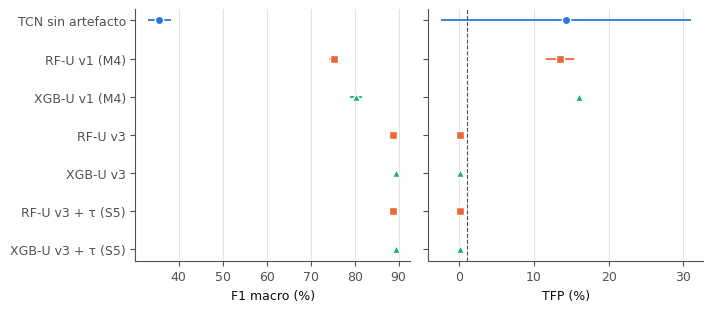

Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/S3_sin_artefacto


In [ ]:
if correr('S3'):
    NOMBRES = {'tcn_u': 'TCN sin artefacto', 'rf_u1': 'RF-U v1 (M4)', 'xgb_u1': 'XGB-U v1 (M4)', 'rf_u3': 'RF-U v3', 'xgb_u3': 'XGB-U v3',
               'rf_u3_tau': 'RF-U v3 + τ (S5)', 'xgb_u3_tau': 'XGB-U v3 + τ (S5)',
               'tcn_v1': 'Ref.: TCN v1 (con artefacto)', 'rf_v1': 'Ref.: MI-LiteRF v1 (con artefacto)'}
    filas = []
    for r in REPS:
        ind1 = leer_json(os.path.join(DIR_V1, f'REP-{r:02d}', 'indicadores.json'))
        for t in ('tcn', 'rf'):
            filas.append({'rep': r, 'modelo': f'{t}_v1', 'f1_macro': ind1[t]['f1_macro'], 'tfp': ind1[t]['tfp'],
                          'ataque_como_normal': resumen_cota(ind1[t]['matriz_confusion'])['flujos_ataque_como_normal'],
                          **{f'pc_{c}': v for c, v in ind1[t]['f1_por_clase'].items()}})
        for n, d in FICHAS_S3[r]['modelos'].items():
            filas.append({'rep': r, 'modelo': n, 'f1_macro': d['f1_macro'], 'tfp': d['tfp'], 'falsas_alarmas': d['falsas_alarmas'],
                          'ataque_como_normal': d['cota']['flujos_ataque_como_normal'], 'clases_con_fallos': d['cota']['clases_con_fallos'],
                          'peor_caso_max': d['cota']['flujos_peor_caso_max'], 'esperado_media': d['cota']['flujos_esperado_media'],
                          'latencia_ms': d.get('latencia_ms', np.nan), 'lote1_ms': d.get('lote1_ms', np.nan), 'respuesta_ms': d.get('respuesta_ms', np.nan),
                          'tamano_kb': d.get('tamano_kb', np.nan), 'tamano_onnx_gzip_kb': d.get('tamano_onnx_gzip_kb', np.nan),
                          'memoria_mb': d.get('memoria_mb', np.nan), 'tau': d.get('tau', ''), **{f'pc_{c}': v for c, v in d['f1_por_clase'].items()}})
    S3 = pd.DataFrame(filas)
    cols_v = ['f1_macro', 'tfp', 'ataque_como_normal', 'peor_caso_max', 'esperado_media', 'latencia_ms', 'lote1_ms', 'respuesta_ms', 'tamano_kb',
              'tamano_onnx_gzip_kb', 'memoria_mb']
    vista = S3.groupby('modelo')[cols_v].agg(['mean', 'std']).reindex(list(NOMBRES)).rename(index=NOMBRES)
    display(vista.round(4))
    piv = lambda c: S3.pivot(index='rep', columns='modelo', values=c).loc[REPS]
    F1, TFP, L1 = piv('f1_macro'), piv('tfp'), piv('lote1_ms')
    PR_F1 = pd.DataFrame([{'comparación': f'{NOMBRES[m]} − TCN sin artefacto (F1)', 'modelo': m, **prueba_pareada(F1['tcn_u'], F1[m], 'two-sided')}
                          for m in ['rf_u1', 'xgb_u1', 'rf_u3', 'xgb_u3']])
    PR_F1['p_holm'] = holm(PR_F1['p'])
    PR_TFP = pd.DataFrame([{'comparación': f'{NOMBRES[m]} < TCN sin artefacto (TFP)', 'modelo': m, **prueba_pareada(TFP['tcn_u'], TFP[m], 'less')}
                           for m in ['rf_u3_tau', 'xgb_u3_tau']])
    PR_TFP['p_holm'] = holm(PR_TFP['p'])
    PR_L1 = pd.DataFrame([{'comparación': f'{NOMBRES[m]} < TCN sin artefacto (lote de 1)', 'modelo': m, **prueba_pareada(L1['tcn_u'], L1[m], 'less')}
                          for m in ['rf_u3', 'xgb_u3']])
    PR_L1['p_holm'] = holm(PR_L1['p'])
    PR_S4 = prueba_pareada(F1['rf_u3'], F1['xgb_u3'], 'two-sided')
    for nombre, P in [('F1 macro (Holm sobre 4)', PR_F1), ('TFP con S5 (Holm sobre 2)', PR_TFP), ('Latencia con lote de 1 (Holm sobre 2)', PR_L1)]:
        print('—', nombre); display(P[['comparación', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'p', 'p_holm']])
    print('— S4: XGB-U v3 − RF-U v3 (F1):', f"{PR_S4['media_d']:+.2f} pts, p = {PR_S4['p']:.4g} ({PR_S4['prueba']})")
    pr = PR_F1.set_index('modelo').loc['rf_u3']
    LECTURA_S3 = {'H.E. 1 sin artefacto (RF-U v3 vs TCN-U)': ('Se sostiene' if pr.p_holm < ALFA and pr.media_d >= MARGEN_RELEVANTE else
                                                             ('En contra' if pr.p_holm < ALFA and pr.media_d <= -MARGEN_RELEVANTE else 'Sin diferencia relevante')),
                  'S5: TFP ≤ 1 % en la prueba': {NOMBRES[m]: bool(TFP[m].mean() <= S5_TFP_MAX) for m in ['rf_u3_tau', 'xgb_u3_tau']},
                  'S5: TFP menor que la TCN-U (p Holm < 0,05)': {NOMBRES[m]: bool(p < ALFA) for m, p in zip(PR_TFP.modelo, PR_TFP.p_holm)},
                  'Latencia lote de 1 menor que la TCN-U': {NOMBRES[m]: bool(p < ALFA) for m, p in zip(PR_L1.modelo, PR_L1.p_holm)}}
    print('Lectura (reglas fijadas):'); print(json.dumps(LECTURA_S3, ensure_ascii=False, indent=1))
    pcl = pd.DataFrame({NOMBRES[m]: [S3[S3.modelo == m][f'pc_{c}'].mean() for c in CLASES] for m in NOMBRES}, index=CLASES)
    display(pcl.round(2))
    if 'C_S3' in globals() and C_S3:
        mostrar_consolidado(C_S3, 'Consolidación sin artefacto (O₁ = TCN-U, O₂ = RF-U v3)')
        print('⚠️ Si la TFP sale con un porcentaje enorme, es la división entre ≈ 0: no reportarlo.')
    # Figura S3 — F1 macro y TFP por modelo (media ± DE)
    orden = ['tcn_u', 'rf_u1', 'xgb_u1', 'rf_u3', 'xgb_u3', 'rf_u3_tau', 'xgb_u3_tau']
    col = {'tcn_u': COLOR['tcn'], 'rf_u1': COLOR['rf'], 'rf_u3': COLOR['rf'], 'rf_u3_tau': COLOR['rf'],
           'xgb_u1': COLOR['xgb'], 'xgb_u3': COLOR['xgb'], 'xgb_u3_tau': COLOR['xgb']}
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.2), sharey=True)
    for ax, c, et in [(axs[0], 'f1_macro', 'F1 macro (%)'), (axs[1], 'tfp', 'TFP (%)')]:
        for i, m in enumerate(orden):
            v = S3[S3.modelo == m][c]
            ax.errorbar(v.mean(), i, xerr=v.std(ddof=1) if len(v) > 1 else None, fmt='o' if m == 'tcn_u' else ('s' if 'rf' in m else '^'),
                        ms=6, color=col[m], mec='white', mew=1, elinewidth=1.3, capsize=0)
        ax.set_xlabel(et); ax.xaxis.set_major_formatter(coma)
        ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color=REJILLA, lw=0.8); ax.set_axisbelow(True)
    axs[1].axvline(S5_TFP_MAX, color=TINTA2, lw=0.8, ls='--')
    axs[0].set_yticks(range(len(orden))); axs[0].set_yticklabels([NOMBRES[m] for m in orden]); axs[0].invert_yaxis()
    fig.tight_layout(); fig.savefig(os.path.join(DIR_S3, 'fig_S3_f1_tfp.png'), dpi=200); plt.show()
    with pd.ExcelWriter(os.path.join(DIR_S3, 'S3_resumen.xlsx')) as xw:
        vista.to_excel(xw, sheet_name='Media y DE'); S3.to_excel(xw, sheet_name='Por REP', index=False)
        for nombre, P in [('F1 (Holm 4)', PR_F1), ('TFP S5 (Holm 2)', PR_TFP), ('Lote 1 (Holm 2)', PR_L1)]:
            P.astype({'ic95_d': str}).to_excel(xw, sheet_name=nombre, index=False)
        pcl.to_excel(xw, sheet_name='F1 por clase')
    guardar_json({'regla': texto_regla_s3(), 'por_rep': S3.to_dict('records'), 'pruebas_f1': PR_F1.to_dict('records'),
                  'pruebas_tfp': PR_TFP.to_dict('records'), 'pruebas_lote1': PR_L1.to_dict('records'), 'prueba_s4': PR_S4,
                  'lectura': LECTURA_S3, 'por_clase': pcl.reset_index().to_dict('records')}, os.path.join(DIR_S3, 'S3_resultados.json'))
    print('Guardado en', DIR_S3)

## Resumen S11d: camino a seguir
Junta S2 y S3 (con S4 y S5) en `mejoras/S11d_resumen.json`. Las decisiones se toman con Ricardo y el profesor; este cuadro solo reúne la evidencia.

In [ ]:
resumen = {'generado': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'), 'reps': REPS}
ruta = os.path.join(DIR_S2, 'S2_resultados.json')
if os.path.exists(ruta):
    R_ = leer_json(ruta); d = pd.DataFrame(R_['por_rep'])
    resumen['S2'] = {'lectura': R_['lectura'], 'T_elegidos': d['T'].map(T_txt).value_counts().to_dict(),
                     **{c: [float(d[c].mean()), float(d[c].std(ddof=1)) if len(d) > 1 else None]
                        for c in ['f1_v3', 'f1_v1', 'f1_tcn', 'fing_v3', 'fing_v1', 'tfp_v3', 'tamano_v3_kb', 'lat1024_v3_ms', 'lote1_v3_ms']},
                     'pruebas': [{k: x[k] for k in ('comparación', 'media_d', 'p_holm')} for x in R_['pruebas']]}
ruta = os.path.join(DIR_S3, 'S3_resultados.json')
if os.path.exists(ruta):
    R_ = leer_json(ruta); d = pd.DataFrame(R_['por_rep'])
    resumen['S3'] = {'lectura': R_['lectura'],
                     'media_por_modelo': d.groupby('modelo')[['f1_macro', 'tfp', 'ataque_como_normal', 'lote1_ms', 'tamano_kb']].mean().round(5).to_dict('index'),
                     'pruebas_f1': [{k: x[k] for k in ('comparación', 'media_d', 'p_holm')} for x in R_['pruebas_f1']],
                     'pruebas_tfp': [{k: x[k] for k in ('comparación', 'media_O1', 'media_O2', 'p_holm')} for x in R_['pruebas_tfp']],
                     'prueba_s4': {k: R_['prueba_s4'][k] for k in ('media_d', 'p', 'prueba')}}
guardar_json(resumen, os.path.join(DIR_MEJ, 'S11d_resumen.json'))
print(json.dumps(resumen, ensure_ascii=False, indent=1, default=str))

{
 "generado": "19/11/2026 14:03",
 "reps": [
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10
 ],
 "S2": {
  "lectura": "v3 mejora a v1",
  "T_elegidos": {
   "sin balanceo": 10
  },
  "f1_v3": [
   93.24375023962833,
   0.1129247633161434
  ],
  "f1_v1": [
   90.31740738144018,
   0.11754195100414466
  ],
  "f1_tcn": [
   68.5299804531817,
   0.7341703819981483
  ],
  "fing_v3": [
   79.22891065034095,
   1.5703337630563459
  ],
  "fing_v1": [
   45.42351832194852,
   1.334902751715429
  ],
  "tfp_v3": [
   0.0,
   0.0
  ],
  "tamano_v3_kb": [
   5503.6619140625,
   291.877082494095
  ],
  "lat1024_v3_ms": [
   0.0028435194263592535,
   0.00017596667221983514
  ],
  "lote1_v3_ms": [
   0.01028155,
   0.0005599461506847481
  ],
  "pruebas": [
   {
    "comparación": "v3 − v1 (F1 macro)",
    "media_d": 2.9263428581881312,
    "p_holm": 9.467756227205207e-13
   },
   {
    "comparación": "v3 − TCN (F1 macro)",
    "media_d": 24.71376978644662,
    "p_holm": 3.1288413125313197e-15
   }

In [ ]:
# (Opcional) Exportar este cuaderno a HTML y descargarlo, cuando haya terminado TODO.
# ⚠️ Primero guarda el cuaderno (Ctrl + S o Archivo → Guardar) y espera unos segundos: el HTML se arma con el .ipynb guardado en Drive
#    (el de S11c salió cortado en M4 REP-09 porque Drive aún no tenía las últimas salidas).
import subprocess
from google.colab import files
ruta_ipynb = '/content/drive/MyDrive/Colab Notebooks/S11d_Mejoras3.ipynb'
ruta_html = '/content/S11d_Mejoras3.html'
subprocess.run(['jupyter', 'nbconvert', '--to', 'html', ruta_ipynb, '--output', ruta_html], check=True)
files.download(ruta_html)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>